In [123]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

In [124]:
sns.set_theme(style= "whitegrid", context="notebook")

In [125]:
file_name = "ProteinAndPathologyQuantifications.csv"
protein_df = pd.read_csv(file_name)

print(protein_df)

      donor_id  donor_name  structure_id structure_acronym  ihc_a_syn  \
0    309335467  H14.09.030         10557               FWM   0.000078   
1    309335480  H14.09.043         10208               PCx   0.000063   
2    309335493  H14.09.056         10557               FWM   0.000064   
3    326765668  H14.09.081         10557               FWM   0.000049   
4    326765668  H14.09.081         10235               TCx   0.000080   
..         ...         ...           ...               ...        ...   
372  326765653  H14.09.066         10208               PCx   0.000046   
373  309335452  H14.09.015         10294               HIP   0.000089   
374  309335489  H14.09.052         10294               HIP   0.000066   
375  309335458  H14.09.021         10208               PCx   0.000793   
376  309335494  H14.09.057         10235               TCx   0.000079   

     ihc_tau2_ffpe  ihc_at8_ffpe   ihc_at8  ihc_ptdp_43_ffpe  ihc_a_beta_ffpe  \
0         0.002358      0.001137  0.000110

In [126]:
donor_counts = protein_df.groupby("structure_acronym")["donor_id"].nunique().reset_index()
donor_counts.columns = ["structure_acronym", "number_of_donors"]

print(donor_counts)

donor_counts.to_excel("Donor_Counts_By_Region.xlsx", index=False)

# Save to CSV
donor_counts.to_csv("Donor_Counts_By_Region.csv", index=False)

  structure_acronym  number_of_donors
0               FWM                93
1               HIP                94
2               PCx                91
3               TCx                99


In [127]:
csv_file = "DonorInformation-2.csv"
features = pd.read_csv(csv_file)

print(features)

      donor_id        name    age sex apo_e4_allele  education_years  \
0    326765665  H14.09.078     87   M             N               16   
1    326765656  H14.09.069  95-99   M             N               17   
2    326765654  H14.09.067     85   M             Y               10   
3    467056391  H15.09.103  90-94   F             N               11   
4    309335447  H14.09.010   100+   M             Y               16   
..         ...         ...    ...  ..           ...              ...   
102  309335458  H14.09.021     88   M             N               12   
103  309335462  H14.09.025     84   M             N               16   
104  309335454  H14.09.017     79   M             N               16   
105  309335486  H14.09.049  95-99   M             N               21   
106  309335442  H14.09.005  90-94   F             Y               14   

     age_at_first_tbi longest_loc_duration  cerad  num_tbi_w_loc  \
0                   0       Unknown or N/A      0              0   

In [128]:
def set_primary_group(row):
    nia = row["nia_reagan"]
    dementia = row["act_demented"]
    if nia in [2, 3] and dementia == "No Dementia":
        return "Resilience-like"
    elif nia in [2, 3] and dementia == "Dementia":
        return "Pathology-positive dementia"
    elif nia in [0, 1] and dementia == "No Dementia":
        return "Low-pathology reference"
    elif nia in [0, 1] and dementia == "Dementia":
        return "Low-pathology dementia"
    else:
        return None
features["primary_group"] = features.apply(set_primary_group, axis=1)

features["primary_group"].value_counts

<bound method IndexOpsMixin.value_counts of 0          Low-pathology reference
1                  Resilience-like
2      Pathology-positive dementia
3          Low-pathology reference
4      Pathology-positive dementia
                  ...             
102         Low-pathology dementia
103         Low-pathology dementia
104                Resilience-like
105        Low-pathology reference
106    Pathology-positive dementia
Name: primary_group, Length: 107, dtype: object>

In [129]:
 print(features.head())

    donor_id        name    age sex apo_e4_allele  education_years  \
0  326765665  H14.09.078     87   M             N               16   
1  326765656  H14.09.069  95-99   M             N               17   
2  326765654  H14.09.067     85   M             Y               10   
3  467056391  H15.09.103  90-94   F             N               11   
4  309335447  H14.09.010   100+   M             Y               16   

   age_at_first_tbi longest_loc_duration  cerad  num_tbi_w_loc  \
0                 0       Unknown or N/A      0              0   
1                12              1-2 min      2              1   
2                72             < 10 sec      3              1   
3                87             < 10 sec      0              1   
4                 0       Unknown or N/A      3              0   

  dsm_iv_clinical_diagnosis  control_set         nincds_arda_diagnosis  \
0               No Dementia           31                   No Dementia   
1               No Dementia       

In [130]:
def set_primary_group(row):
    nia = row["nia_reagan"]
    dementia = row["act_demented"]
    
    if nia in [2, 3] and dementia == "No Dementia":
        return "Resilience-like"
    elif nia in [2, 3] and dementia == "Dementia":
        return "Pathology-positive dementia"
    elif nia in [0, 1] and dementia == "No Dementia":
        return "Low-pathology reference"
    elif nia in [0, 1] and dementia == "Dementia":
        return "Low-pathology dementia"
    else:
        return None


features["primary_group"] = features.apply(set_primary_group, axis=1)


primary_counts = features["primary_group"].value_counts().reset_index()
primary_counts.columns = ["Primary Group", "Number of Individuals"]

display(primary_counts)


,Primary Group,Number of Individuals
0,Low-pathology reference,36
1,Pathology-positive dementia,31
2,Resilience-like,21
3,Low-pathology dementia,19


In [131]:
features["primary_group"] = features.apply(set_primary_group, axis=1)


merged_df = pd.merge(
    protein_df, 
    features[["donor_id", "primary_group"]], 
    on="donor_id", 
    how="left"
)


region_counts = pd.crosstab(
    merged_df["structure_acronym"], 
    merged_df["primary_group"]
)


region_counts = region_counts.reset_index()
region_counts.rename(columns={"structure_acronym": "Brain Region (structure_acronym)"}, inplace=True)

display(region_counts)


region_counts.to_excel("Donor_Counts_By_Region_And_Group.xlsx", index=False)
region_counts.to_csv("Donor_Counts_By_Region_And_Group.csv", index=False)

print("Exported successfully with structure_acronym included!")

primary_group,Brain Region (structure_acronym),Low-pathology dementia,Low-pathology reference,Pathology-positive dementia,Resilience-like
0,FWM,17,28,28,20
1,HIP,14,32,29,19
2,PCx,17,27,27,20
3,TCx,19,31,29,20


Exported successfully with structure_acronym included!


In [132]:


protein_df = pd.read_csv(file_name)
donor_df = pd.read_csv(csv_file)


def set_primary_group(row):
    nia = row["nia_reagan"]
    dementia = row["act_demented"]
    if nia in [2, 3] and dementia == "No Dementia":
        return "Resilience-like"
    elif nia in [2, 3] and dementia == "Dementia":
        return "Pathology-positive dementia"
    elif nia in [0, 1] and dementia == "No Dementia":
        return "Low-pathology reference"
    elif nia in [0, 1] and dementia == "Dementia":
        return "Low-pathology dementia"
    else:
        return None


def set_strict_group(row):
    braak = row["braak"]
    cerad = row["cerad"]
    dementia = row["act_demented"]
    if braak in [5, 6] and cerad in [2, 3] and dementia == "No Dementia":
        return "Strict resilience-like"
    elif braak in [5, 6] and cerad in [2, 3] and dementia == "Dementia":
        return "Strict pathology-positive dementia"
    else:
        return None


donor_df["primary_group"] = donor_df.apply(set_primary_group, axis=1)
donor_df["strict_group"] = donor_df.apply(set_strict_group, axis=1)


retained_donor_cols = [
    "donor_id",
    "primary_group",
    "strict_group",
    "act_demented",     
    "braak",            
    "cerad",           
    "nia_reagan",      
     "age",
     "sex", 
    "education_years",  
    "apo_e4_allele",     
    "ever_tbi_w_loc"  
]


available_cols = [col for col in retained_donor_cols if col in donor_df.columns]


merged_df = pd.merge(
    protein_df,
    donor_df[available_cols],
    on="donor_id",
    how="left"
)

print("--- Primary Group Counts across Regional Records ---")
print(merged_df["primary_group"].value_counts(dropna=False))

print("--- Strict Group Counts across Regional Records ---")
print(merged_df["strict_group"].value_counts(dropna=False))


display(merged_df.head())


merged_df.to_csv("Regional_Protein_Pathology_With_Donor_Metadata.csv", index=False)

--- Primary Group Counts across Regional Records ---
primary_group
Low-pathology reference        118
Pathology-positive dementia    113
Resilience-like                 79
Low-pathology dementia          67
Name: count, dtype: int64
--- Strict Group Counts across Regional Records ---
strict_group
None                                  271
Strict pathology-positive dementia     83
Strict resilience-like                 23
Name: count, dtype: int64


,donor_id,donor_name,structure_id,structure_acronym,ihc_a_syn,ihc_tau2_ffpe,ihc_at8_ffpe,ihc_at8,ihc_ptdp_43_ffpe,ihc_a_beta_ffpe,...,strict_group,act_demented,braak,cerad,nia_reagan,age,sex,education_years,apo_e4_allele,ever_tbi_w_loc
0,309335467,H14.09.030,10557,FWM,0.000078,0.002358,0.001137,0.000110,0.001259,0.008335,...,None,No Dementia,3,3,2,90-94,F,15,Y,N
1,309335480,H14.09.043,10208,PCx,0.000063,0.002762,0.001272,0.000164,0.002354,0.005047,...,None,Dementia,0,0,0,87,F,12,N,Y
2,309335493,H14.09.056,10557,FWM,0.000064,0.003468,0.013787,0.016023,0.001708,0.007365,...,Strict pathology-positive dementia,Dementia,5,3,3,100+,F,17,NaN,N
3,326765668,H14.09.081,10557,FWM,0.000049,0.003035,0.001707,0.000137,0.001729,0.004046,...,None,No Dementia,3,2,2,95-99,M,13,Y,Y
4,326765668,H14.09.081,10235,TCx,0.000080,0.002088,0.004489,0.000062,0.001513,0.015809,...,None,No Dementia,3,2,2,95-99,M,13,Y,Y


In [133]:
merged_check = pd.merge(
    protein_df,
    donor_df[available_cols],
    on="donor_id",
    how="left",
    indicator=True
)


match_counts = merged_check["_merge"].value_counts()
print("--- Merge Status Counts ---")
print(match_counts)


unmatched_records = merged_check[merged_check["_merge"] != "both"]
unmatched_count = len(unmatched_records)

print(f"\nTotal regional protein records: {len(protein_df)}")
print(f"Successfully matched records: {len(merged_check) - unmatched_count}")
print(f"Failed / Unmatched records: {unmatched_count}")


if unmatched_count > 0:
    print("\nWarning: The following donor_ids in protein_df failed to match:")
    print(unmatched_records[["donor_id", "structure_acronym"]])
else:
    print("\n Success: Every single regional protein/pathology record successfully matched a donor!")

--- Merge Status Counts ---
_merge
both          377
left_only       0
right_only      0
Name: count, dtype: int64

Total regional protein records: 377
Successfully matched records: 377
Failed / Unmatched records: 0

 Success: Every single regional protein/pathology record successfully matched a donor!


In [134]:
protein_df = pd.read_csv("ProteinAndPathologyQuantifications.csv")


metadata_cols = [
    "donor_id", "donor_name", "structure_id", "structure_acronym",
    "primary_group", "strict_group", "act_demented", "braak", "cerad",
    "nia_reagan", "age", "sex", "education_years", "apo_e4_allele", "ever_tbi_w_loc"
]

measurement_cols = [col for col in protein_df.columns if col not in metadata_cols]

total_records = len(protein_df)

missing_summary = pd.DataFrame({
    "Variable": measurement_cols,
    "Available Values": protein_df[measurement_cols].notnull().sum().values,
    "Missing Values": protein_df[measurement_cols].isnull().sum().values,
    "Percent Missing (%)": (protein_df[measurement_cols].isnull().sum() / total_records * 100).round(2).values
})


missing_summary = missing_summary.sort_values(by="Percent Missing (%)", ascending=False).reset_index(drop=True)


display(missing_summary)

missing_summary.to_excel("Protein_Pathology_Missing_Data_Summary.xlsx", index=False)
missing_summary.to_csv("Protein_Pathology_Missing_Data_Summary.csv", index=False)
print("Missing-data summary created and saved successfully!")

,Variable,Available Values,Missing Values,Percent Missing (%)
0,isoprostane_pg_per_mg,138,239,63.40
1,a_syn_pg_per_mg,321,56,14.85
2,bdnf_pg_per_mg,323,54,14.32
3,tau_ng_per_mg,326,51,13.53
4,ptau_over_tau_ratio,326,51,13.53
5,ab42_over_ab40_ratio,327,50,13.26
6,il_10_pg_per_mg,332,45,11.94
7,il_1b_pg_per_mg,332,45,11.94
8,il_6_pg_per_mg,332,45,11.94
9,vegf_pg_per_mg,332,45,11.94


Missing-data summary created and saved successfully!


In [135]:
import pandas as pd
import numpy as np


protein_df = pd.read_csv("ProteinAndPathologyQuantifications.csv")
donor_df = pd.read_csv("DonorInformation-2.csv")


def set_primary_group(row):
    nia = row["nia_reagan"]
    dementia = row["act_demented"]
    if nia in [2, 3] and dementia == "No Dementia":
        return "Resilience-like"
    elif nia in [2, 3] and dementia == "Dementia":
        return "Pathology-positive dementia"
    elif nia in [0, 1] and dementia == "No Dementia":
        return "Low-pathology reference"
    elif nia in [0, 1] and dementia == "Dementia":
        return "Low-pathology dementia"
    else:
        return None

donor_df["primary_group"] = donor_df.apply(set_primary_group, axis=1)


merged_df = pd.merge(
    protein_df,
    donor_df[["donor_id", "primary_group"]],
    on="donor_id",
    how="left"
)


hip_df = merged_df[merged_df["structure_acronym"] == "HIP"].copy()


hip_df.to_csv("Hippocampus_Working_Dataset.csv", index=False)
hip_df.to_excel("Hippocampus_Working_Dataset.xlsx", index=False)
print("Hippocampus working file created and saved successfully.")


hip_donor_counts = hip_df["primary_group"].value_counts().reset_index()
hip_donor_counts.columns = ["Primary Group", "Donor Count (N)"]

print("\n--- Hippocampus Donor Counts by Primary Group ---")
print(hip_donor_counts)


metadata_cols = [
    "donor_id", "donor_name", "structure_id", "structure_acronym",
    "primary_group", "strict_group", "act_demented", "braak", "cerad",
    "nia_reagan", "age", "sex", "education_years", "apo_e4_allele", "ever_tbi_w_loc"
]

measurement_cols = [col for col in hip_df.columns if col not in metadata_cols]

stats_list = []

for group_name, group_data in hip_df.groupby("primary_group"):
    for var in measurement_cols:
        series = group_data[var]
        stats_list.append({
            "Primary Group": group_name,
            "Measurement Variable": var,
            "Available N": series.notnull().sum(),
            "Mean": series.mean(),
            "Median": series.median(),
            "Std Dev": series.std(),
            "Min": series.min(),
            "Max": series.max()
        })


hip_desc_stats = pd.DataFrame(stats_list)


numeric_cols = ["Mean", "Median", "Std Dev", "Min", "Max"]
hip_desc_stats[numeric_cols] = hip_desc_stats[numeric_cols].round(4)


display(hip_desc_stats.head(15))


hip_desc_stats.to_csv("HIP_Protein_Descriptive_Stats_By_Group.csv", index=False)
hip_desc_stats.to_excel("HIP_Protein_Descriptive_Stats_By_Group.xlsx", index=False)
print("\nHippocampus descriptive statistics calculated and exported successfully!")

Hippocampus working file created and saved successfully.

--- Hippocampus Donor Counts by Primary Group ---
                 Primary Group  Donor Count (N)
0      Low-pathology reference               32
1  Pathology-positive dementia               29
2              Resilience-like               19
3       Low-pathology dementia               14


,Primary Group,Measurement Variable,Available N,Mean,Median,Std Dev,Min,Max
0,Low-pathology dementia,ihc_a_syn,14,0.0020,0.0001,0.0044,0.0000,0.0156
1,Low-pathology dementia,ihc_tau2_ffpe,13,0.0075,0.0051,0.0059,0.0014,0.0184
2,Low-pathology dementia,ihc_at8_ffpe,13,0.0186,0.0145,0.0132,0.0023,0.0472
3,Low-pathology dementia,ihc_at8,14,0.0290,0.0257,0.0250,0.0010,0.0704
4,Low-pathology dementia,ihc_ptdp_43_ffpe,14,0.0019,0.0018,0.0010,0.0008,0.0036
5,Low-pathology dementia,ihc_a_beta_ffpe,14,0.0073,0.0067,0.0032,0.0034,0.0140
6,Low-pathology dementia,ihc_a_beta,14,0.0064,0.0063,0.0033,0.0013,0.0128
7,Low-pathology dementia,ihc_iba1_ffpe,14,0.0711,0.0714,0.0287,0.0335,0.1124
8,Low-pathology dementia,ihc_gfap_ffpe,14,0.0572,0.0517,0.0153,0.0404,0.0868
9,Low-pathology dementia,ptau_ng_per_mg,13,2.0745,1.8408,1.1521,0.8795,4.2509



Hippocampus descriptive statistics calculated and exported successfully!


In [136]:
import os
import numpy as np
import pandas as pd
from IPython.display import FileLink, display

#Load The Datasets

protein_df = pd.read_csv("ProteinAndPathologyQuantifications.csv")
donor_df = pd.read_csv("DonorInformation-2.csv")

#Define Primary Groups

def set_primary_group(row):
    nia = row["nia_reagan"]
    dementia = row["act_demented"]

    if nia in [2, 3] and dementia == "No Dementia":
        return "Resilience-like"
    elif nia in [2, 3] and dementia == "Dementia":
        return "Pathology-positive dementia"
    elif nia in [0, 1] and dementia == "No Dementia":
        return "Low-pathology reference"
    elif nia in [0, 1] and dementia == "Dementia":
        return "Low-pathology dementia"
    else:
        return None


donor_df["primary_group"] = donor_df.apply(set_primary_group, axis=1)

# Merging the protein analysis data with the donor data & creating the hippocampus data variable

merged_df = pd.merge(
    protein_df,
    donor_df[["donor_id", "primary_group"]],
    on="donor_id",
    how="left",
)

target_groups = [
    "Resilience-like",
    "Pathology-positive dementia",
    "Low-pathology reference",
]

hip_df = merged_df[
    (merged_df["structure_acronym"] == "HIP")
    & (merged_df["primary_group"].isin(target_groups))
].copy()

# Identifying the different headings in the table

metadata_cols = [
    "donor_id",
    "donor_name",
    "structure_id",
    "structure_acronym",
    "primary_group",
    "strict_group",
    "act_demented",
    "braak",
    "cerad",
    "nia_reagan",
    "age",
    "sex",
    "education_years",
    "apo_e4_allele",
    "ever_tbi_w_loc",
]
measurement_cols = [col for col in hip_df.columns if col not in metadata_cols]

# Call to calculate the missing data
missing_records = []

#Code to filter hippocampus only data
for group_name in target_groups:
    group_data = hip_df[hip_df["primary_group"] == group_name]
    total_n = len(group_data)

# Loops through each protein measurement variable 

    for var in measurement_cols:
        available_n = group_data[var].notnull().sum()
        #Calculates the valid values 
        missing_n = group_data[var].isnull().sum()
        #Calculates the missing value
        pct_missing = (missing_n / total_n * 100) if total_n > 0 else 0
        # Calculates the percentage value

        missing_records.append({
            "Primary Group": group_name,
            "Total Group Donors (N)": total_n,
            "Variable": var,
            "Available Values": available_n,
            "Missing Values": missing_n,
            "Percent Missing (%)": round(pct_missing, 2),
        })

# Contains all the calculated statistics for each protein

summary_df = pd.DataFrame(missing_records)


wide_summary = summary_df.pivot(
    index="Variable", columns="Primary Group", values="Available Values"
)


total_hip_donors = len(hip_df)
#Calculates the total number of hippocampus donors
overall_missing = (
    hip_df[measurement_cols].isnull().sum() / total_hip_donors * 100
).round(2)
wide_summary["Overall Missing (%)"] = overall_missing
# Computes overall missing percentage

wide_summary = wide_summary.sort_values(by="Overall Missing (%)")


print("--- Side-by-Side Available Values (N) & Overall Missing (%) ---")
display(wide_summary)


excel_file = "HIP_Missing_Data_Summary.xlsx"
csv_file = "HIP_Missing_Data_Summary.csv"

wide_summary.to_excel(excel_file)
summary_df.to_csv(csv_file, index=False)

print(f"\nFiles exported successfully to: {os.path.abspath(excel_file)}")
display(FileLink(excel_file))

--- Side-by-Side Available Values (N) & Overall Missing (%) ---


Primary Group,Low-pathology reference,Pathology-positive dementia,Resilience-like,Overall Missing (%)
Variable,,,,
ihc_a_beta,32,29,19,0.00
ihc_a_syn,32,29,19,0.00
ihc_at8,32,29,19,0.00
ihc_at8_ffpe,26,27,19,10.00
ihc_iba1_ffpe,26,27,19,10.00
ihc_ptdp_43_ffpe,26,27,19,10.00
ihc_gfap_ffpe,26,27,17,12.50
ihc_tau2_ffpe,24,27,19,12.50
ab42_over_ab40_ratio,26,26,17,13.75



Files exported successfully to: /home/93252705-5e40-40c3-a3b6-36f1c71c49de/Allen Dataset/HIP_Missing_Data_Summary.xlsx


/home/93252705-5e40-40c3-a3b6-36f1c71c49de/Allen Dataset/HIP_Missing_Data_Summary.xlsx

/tmp/ipykernel_521/2708389798.py:40: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/tmp/ipykernel_521/2708389798.py:71: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(


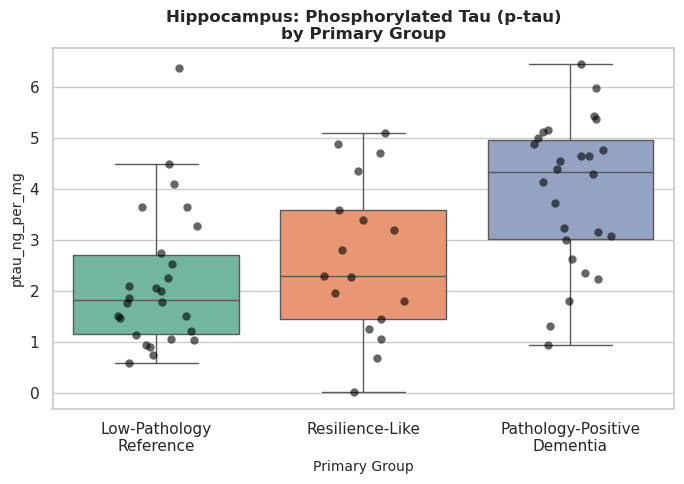

/home/93252705-5e40-40c3-a3b6-36f1c71c49de/Allen Dataset/HIP_ptau_ng_per_mg_distribution.pdf

/tmp/ipykernel_521/2708389798.py:40: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/tmp/ipykernel_521/2708389798.py:71: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(


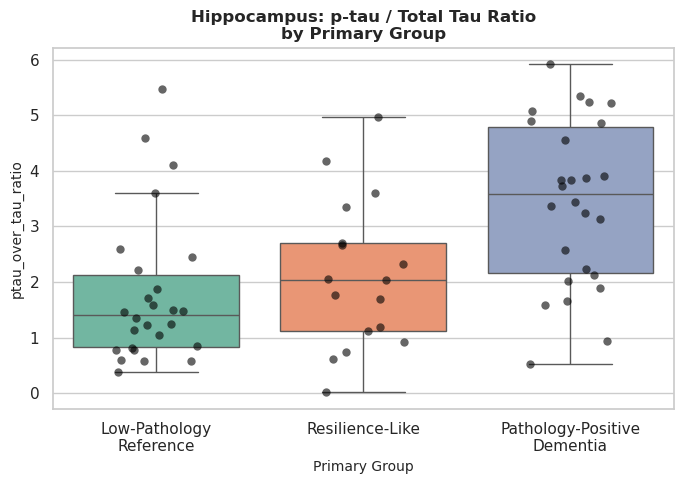

/home/93252705-5e40-40c3-a3b6-36f1c71c49de/Allen Dataset/HIP_ptau_over_tau_ratio_distribution.pdf

/tmp/ipykernel_521/2708389798.py:40: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/tmp/ipykernel_521/2708389798.py:71: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(


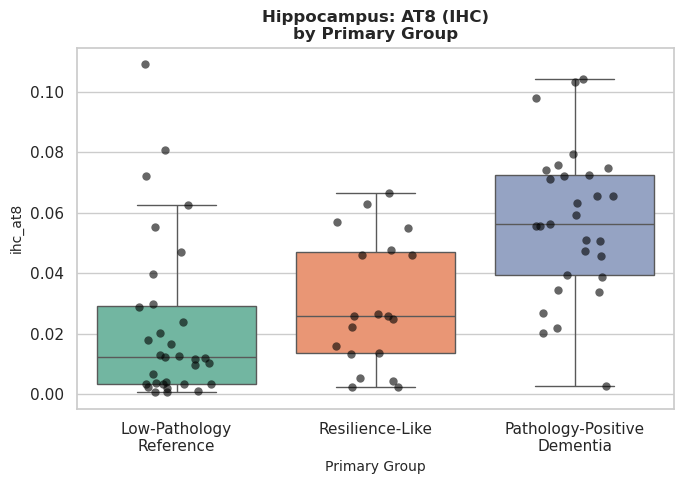

/home/93252705-5e40-40c3-a3b6-36f1c71c49de/Allen Dataset/HIP_ihc_at8_distribution.pdf

/tmp/ipykernel_521/2708389798.py:40: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/tmp/ipykernel_521/2708389798.py:71: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(


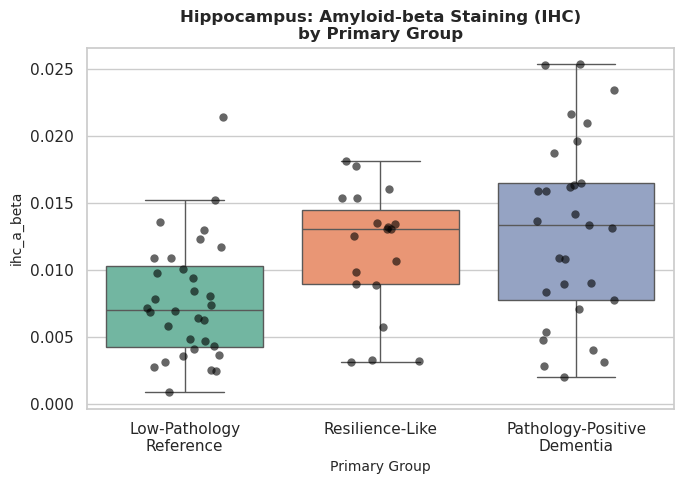

/home/93252705-5e40-40c3-a3b6-36f1c71c49de/Allen Dataset/HIP_ihc_a_beta_distribution.pdf

/tmp/ipykernel_521/2708389798.py:40: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/tmp/ipykernel_521/2708389798.py:71: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(


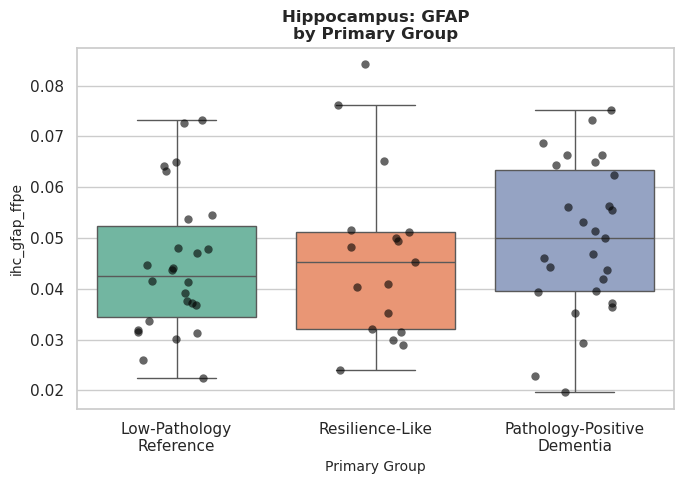

/home/93252705-5e40-40c3-a3b6-36f1c71c49de/Allen Dataset/HIP_ihc_gfap_ffpe_distribution.pdf

/tmp/ipykernel_521/2708389798.py:40: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/tmp/ipykernel_521/2708389798.py:71: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(


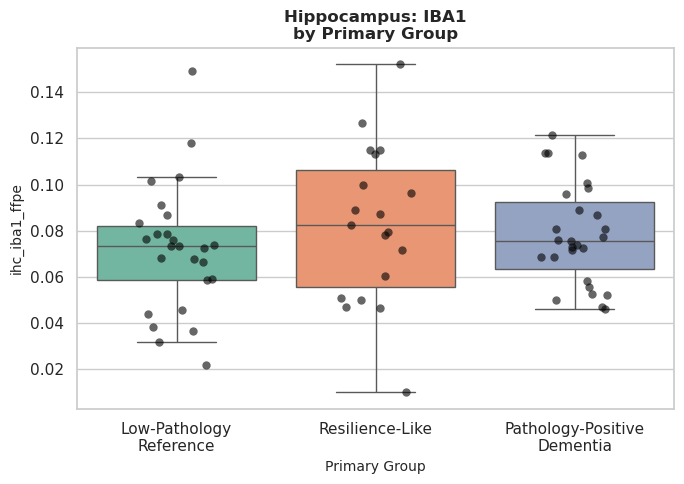

/home/93252705-5e40-40c3-a3b6-36f1c71c49de/Allen Dataset/HIP_ihc_iba1_ffpe_distribution.pdf

/tmp/ipykernel_521/2708389798.py:40: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/tmp/ipykernel_521/2708389798.py:71: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(


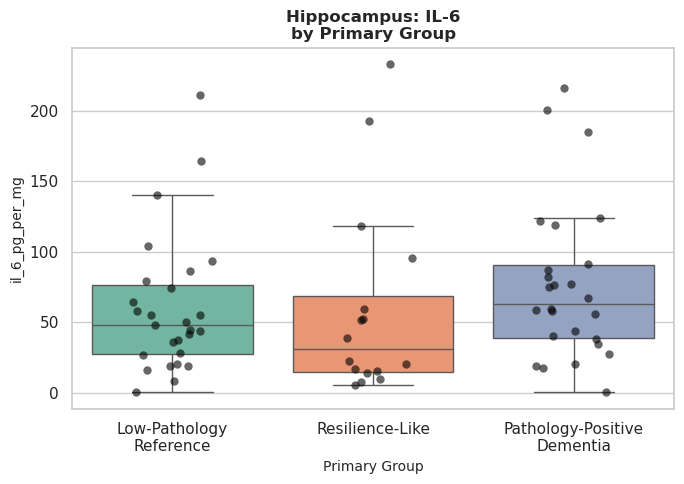

/home/93252705-5e40-40c3-a3b6-36f1c71c49de/Allen Dataset/HIP_il_6_pg_per_mg_distribution.pdf

/tmp/ipykernel_521/2708389798.py:40: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/tmp/ipykernel_521/2708389798.py:71: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(


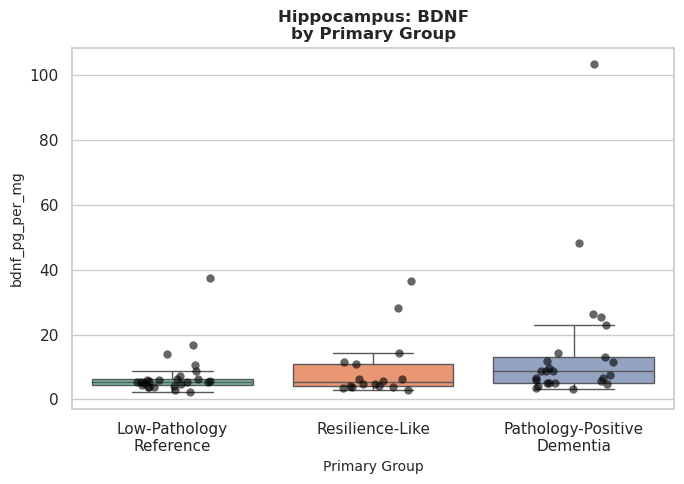

/home/93252705-5e40-40c3-a3b6-36f1c71c49de/Allen Dataset/HIP_bdnf_pg_per_mg_distribution.pdf

In [137]:
import os
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
from IPython.display import FileLink, display

# Define the 8 specific markers and their clean plot titles
marker_dict = {
    "ptau_ng_per_mg": "Phosphorylated Tau (p-tau)",
    "ptau_over_tau_ratio": "p-tau / Total Tau Ratio",
    "ihc_at8": "AT8 (IHC)",  
    "ihc_a_beta": "Amyloid-beta Staining (IHC)", 
    "ihc_gfap_ffpe": "GFAP",
    "ihc_iba1_ffpe": "IBA1",
    "il_6_pg_per_mg": "IL-6",
    "bdnf_pg_per_mg": "BDNF",
}

# The headings for the proteins in the graph were changed in order to ensure that they are more readable

# Specify the 3 target groups that should be displayed in this order
target_groups = [
    "Low-pathology reference",
    "Resilience-like",
    "Pathology-positive dementia",
]

# Filter hippocampal data for target groups
plot_df = hip_df[hip_df["primary_group"].isin(target_groups)].copy()

# Generate a separate plot for each marker
for marker_col, marker_title in marker_dict.items():
    if marker_col not in plot_df.columns:
        print(f"Warning: Column '{marker_col}' not found in DataFrame. Skipping...")
        continue

    fig, ax = plt.subplots(figsize=(7, 5))

# Summary: Boxplot showing median, IQR, and group distribution
    sns.boxplot(
        data=plot_df,
        x="primary_group",
        y=marker_col,
        order=target_groups,
        palette="Set2",
        showfliers=False,  # Suppresses duplicate outlier dots from the boxplot
        ax=ax,
    )

    # Individual donor values: Stripplot (jitter plot) showing every single donor dot
    sns.stripplot(
        data=plot_df,
        x="primary_group",
        y=marker_col,
        order=target_groups,
        color="black",
        alpha=0.6,
        jitter=0.2,
        size=6,
        ax=ax,
    )

    # Labels and Titles
    ax.set_title(
        f"Hippocampus: {marker_title}\nby Primary Group",
        fontsize=12,
        fontweight="bold",
    )
    ax.set_xlabel("Primary Group", fontsize=10)
    ax.set_ylabel(marker_col, fontsize=10)
    ax.set_xticklabels(
        ["Low-Pathology\nReference", "Resilience-Like", "Pathology-Positive\nDementia"]
    )

    plt.tight_layout()

    # Save each graph as an individual PDF
    pdf_filename = f"HIP_{marker_col}_distribution.pdf"
    plt.savefig(pdf_filename, format="pdf", bbox_inches="tight")

    # Display plot in Jupyter Notebook
    plt.show()

    # Display downloadable PDF link
    display(FileLink(pdf_filename))

In [138]:
import pandas as pd
from IPython.display import display

# Define the 8 specific markers and clean display names
marker_dict = {
    "ptau_ng_per_mg": "Phosphorylated Tau (p-tau)",
    "ptau_over_tau_ratio": "p-tau / Total Tau Ratio",
    "ihc_at8": "AT8 (IHC)",  # Use 'ihc_at8_ffpe' if applicable in your dataset
    "ihc_a_beta": "Amyloid-beta Staining (IHC)",  # Use 'ihc_a_beta_ffpe' if applicable
    "ihc_gfap_ffpe": "GFAP",
    "ihc_iba1_ffpe": "IBA1",
    "il_6_pg_per_mg": "IL-6",
    "bdnf_pg_per_mg": "BDNF",
}

# Define the target primary groups
target_groups = [
    "Low-pathology reference",
    "Resilience-like",
    "Pathology-positive dementia",
]

#  Filter hippocampal data for target groups
table_df = hip_df[hip_df["primary_group"].isin(target_groups)].copy()

# Loop through each marker and print its individual donor table
for marker_col, marker_title in marker_dict.items():
  if marker_col not in table_df.columns:
    print(
        f"Warning: Column '{marker_col}' not found in DataFrame."
        " Skipping...\n"
    )
    continue

  print("=" * 70)
  print(f" DATA TABLE FOR MARKER: {marker_title} ({marker_col})")
  print("=" * 70)

  # Extract relevant columns
  donor_table = table_df[["donor_id", "primary_group", marker_col]].copy()

  # Sort by primary group and donor_id for clean reading
  donor_table = donor_table.sort_values(
      by=["primary_group", "donor_id"]
  ).reset_index(drop=True)

  # Display table in Jupyter Notebook
  display(donor_table)
  print("\n\n")

 DATA TABLE FOR MARKER: Phosphorylated Tau (p-tau) (ptau_ng_per_mg)


,donor_id,primary_group,ptau_ng_per_mg
0,309335441,Low-pathology reference,4.485088
1,309335443,Low-pathology reference,NaN
2,309335451,Low-pathology reference,1.793604
3,309335452,Low-pathology reference,1.519767
4,309335460,Low-pathology reference,2.051438
...,...,...,...
75,326765682,Resilience-like,0.688055
76,326765683,Resilience-like,2.796675
77,326765688,Resilience-like,NaN
78,467056397,Resilience-like,1.805598





 DATA TABLE FOR MARKER: p-tau / Total Tau Ratio (ptau_over_tau_ratio)


,donor_id,primary_group,ptau_over_tau_ratio
0,309335441,Low-pathology reference,4.587877
1,309335443,Low-pathology reference,NaN
2,309335451,Low-pathology reference,1.465191
3,309335452,Low-pathology reference,1.047478
4,309335460,Low-pathology reference,1.144112
...,...,...,...
75,326765682,Resilience-like,0.615156
76,326765683,Resilience-like,2.045638
77,326765688,Resilience-like,NaN
78,467056397,Resilience-like,1.194777





 DATA TABLE FOR MARKER: AT8 (IHC) (ihc_at8)


...

,donor_id,primary_group,ihc_iba1_ffpe
0,309335441,Low-pathology reference,NaN
1,309335443,Low-pathology reference,NaN
2,309335451,Low-pathology reference,0.021788
3,309335452,Low-pathology reference,0.086936
4,309335460,Low-pathology reference,0.036507
...,...,...,...
75,326765682,Resilience-like,0.078250
76,326765683,Resilience-like,0.099577
77,326765688,Resilience-like,0.046435
78,467056397,Resilience-like,0.114840





 DATA TABLE FOR MARKER: IL-6 (il_6_pg_per_mg)


,donor_id,primary_group,il_6_pg_per_mg
0,309335441,Low-pathology reference,15.96
1,309335443,Low-pathology reference,NaN
2,309335451,Low-pathology reference,42.02
3,309335452,Low-pathology reference,19.32
4,309335460,Low-pathology reference,8.30
...,...,...,...
75,326765682,Resilience-like,95.94
76,326765683,Resilience-like,17.10
77,326765688,Resilience-like,NaN
78,467056397,Resilience-like,20.34





 DATA TABLE FOR MARKER: BDNF (bdnf_pg_per_mg)


,donor_id,primary_group,bdnf_pg_per_mg
0,309335441,Low-pathology reference,5.317180
1,309335443,Low-pathology reference,NaN
2,309335451,Low-pathology reference,5.267780
3,309335452,Low-pathology reference,2.948190
4,309335460,Low-pathology reference,8.796190
...,...,...,...
75,326765682,Resilience-like,36.458590
76,326765683,Resilience-like,4.607390
77,326765688,Resilience-like,NaN
78,467056397,Resilience-like,6.249230


/tmp/ipykernel_521/553576527.py:41: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/tmp/ipykernel_521/553576527.py:70: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(


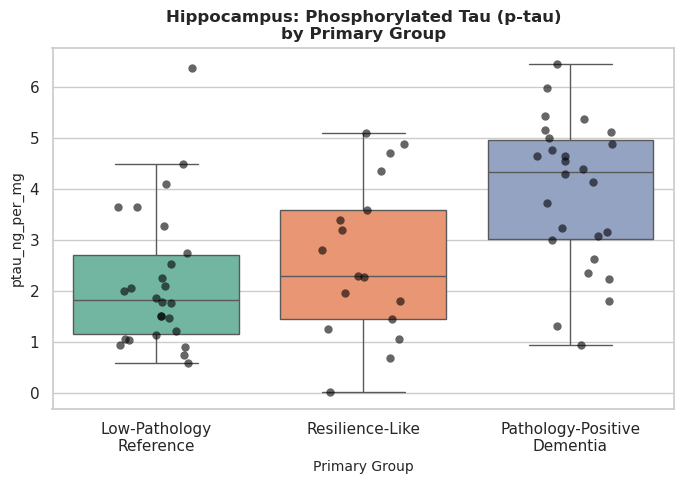

Data Table CSV for: Phosphorylated Tau (p-tau) (ptau_ng_per_mg)


/home/93252705-5e40-40c3-a3b6-36f1c71c49de/Allen Dataset/HIP_Donor_Table_ptau_ng_per_mg.csv

------------------------------------------------------------


/tmp/ipykernel_521/553576527.py:41: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/tmp/ipykernel_521/553576527.py:70: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(


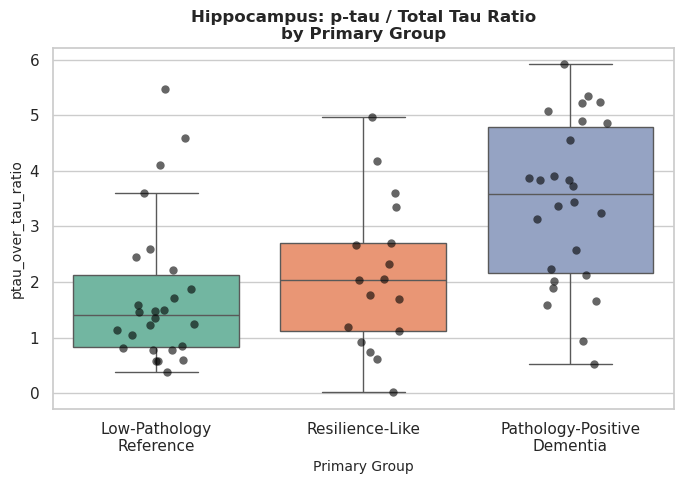

Data Table CSV for: p-tau / Total Tau Ratio (ptau_over_tau_ratio)


/home/93252705-5e40-40c3-a3b6-36f1c71c49de/Allen Dataset/HIP_Donor_Table_ptau_over_tau_ratio.csv

------------------------------------------------------------


/tmp/ipykernel_521/553576527.py:41: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/tmp/ipykernel_521/553576527.py:70: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(


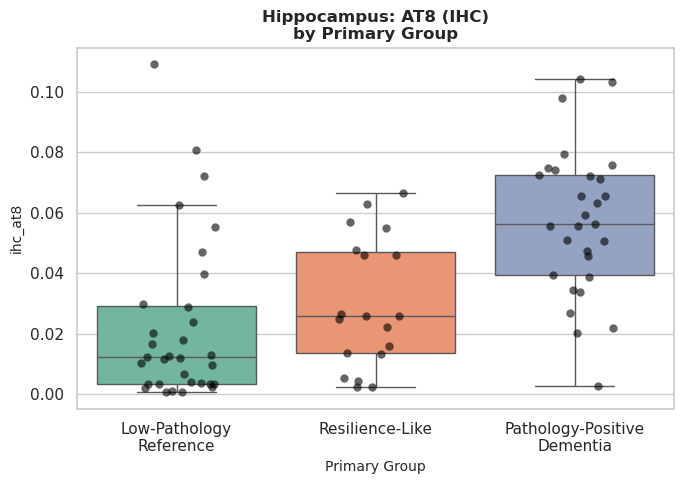

Data Table CSV for: AT8 (IHC) (ihc_at8)


/home/93252705-5e40-40c3-a3b6-36f1c71c49de/Allen Dataset/HIP_Donor_Table_ihc_at8.csv

------------------------------------------------------------


/tmp/ipykernel_521/553576527.py:41: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/tmp/ipykernel_521/553576527.py:70: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(


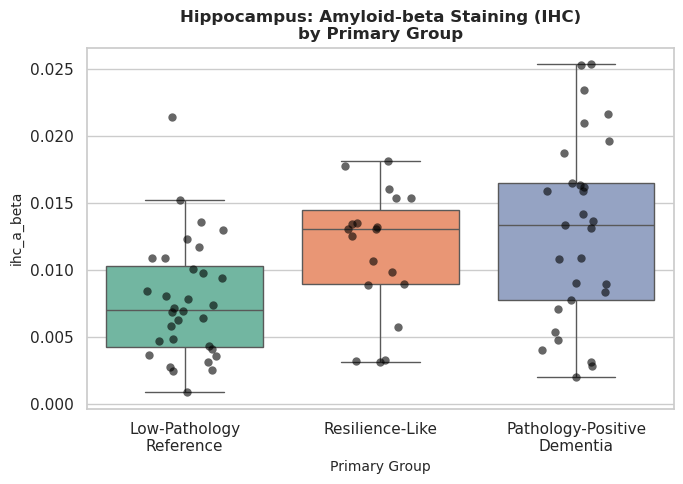

Data Table CSV for: Amyloid-beta Staining (IHC) (ihc_a_beta)


/home/93252705-5e40-40c3-a3b6-36f1c71c49de/Allen Dataset/HIP_Donor_Table_ihc_a_beta.csv

------------------------------------------------------------


/tmp/ipykernel_521/553576527.py:41: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/tmp/ipykernel_521/553576527.py:70: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(


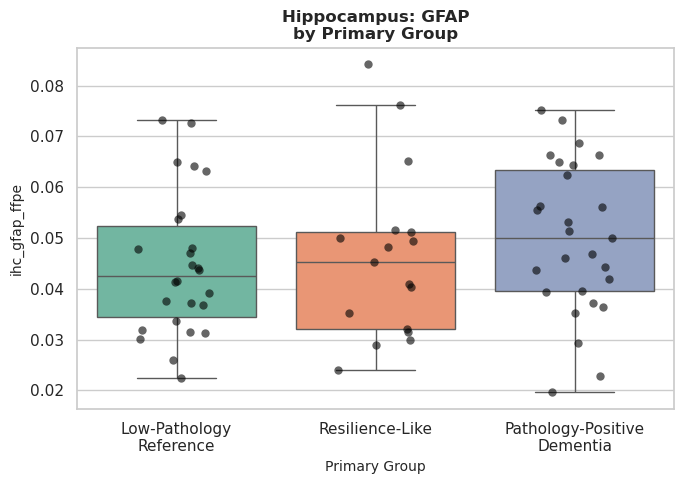

Data Table CSV for: GFAP (ihc_gfap_ffpe)


/home/93252705-5e40-40c3-a3b6-36f1c71c49de/Allen Dataset/HIP_Donor_Table_ihc_gfap_ffpe.csv

------------------------------------------------------------


/tmp/ipykernel_521/553576527.py:41: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/tmp/ipykernel_521/553576527.py:70: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(


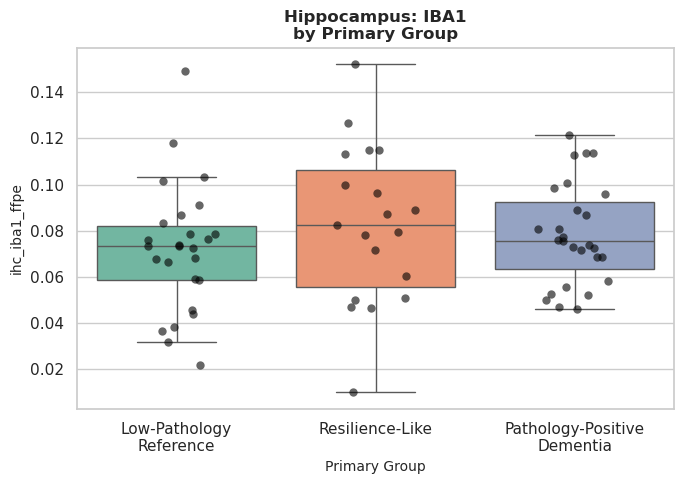

Data Table CSV for: IBA1 (ihc_iba1_ffpe)


/home/93252705-5e40-40c3-a3b6-36f1c71c49de/Allen Dataset/HIP_Donor_Table_ihc_iba1_ffpe.csv

------------------------------------------------------------


/tmp/ipykernel_521/553576527.py:41: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/tmp/ipykernel_521/553576527.py:70: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(


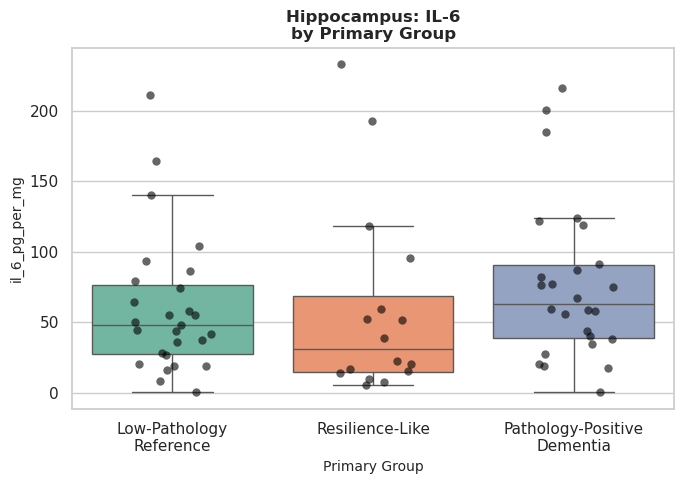

Data Table CSV for: IL-6 (il_6_pg_per_mg)


/home/93252705-5e40-40c3-a3b6-36f1c71c49de/Allen Dataset/HIP_Donor_Table_il_6_pg_per_mg.csv

------------------------------------------------------------


/tmp/ipykernel_521/553576527.py:41: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/tmp/ipykernel_521/553576527.py:70: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(


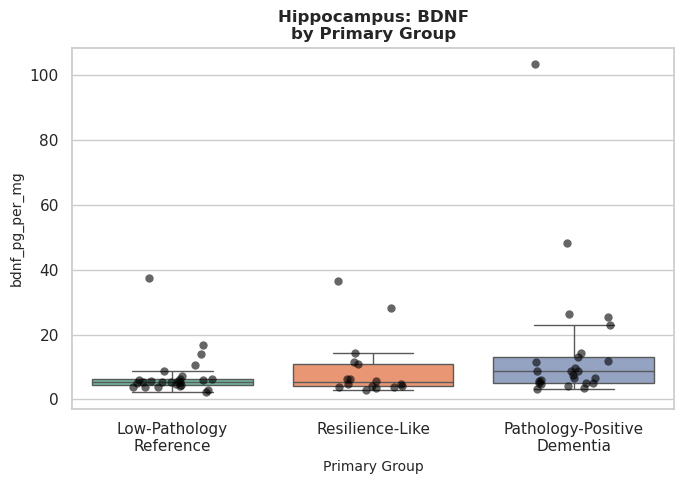

Data Table CSV for: BDNF (bdnf_pg_per_mg)


/home/93252705-5e40-40c3-a3b6-36f1c71c49de/Allen Dataset/HIP_Donor_Table_bdnf_pg_per_mg.csv

------------------------------------------------------------


In [139]:
import os
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from IPython.display import FileLink, display

# Define the 8 specific markers and clean display names
marker_dict = {
    "ptau_ng_per_mg": "Phosphorylated Tau (p-tau)",
    "ptau_over_tau_ratio": "p-tau / Total Tau Ratio",
    "ihc_at8": "AT8 (IHC)",  # Use 'ihc_at8_ffpe' if that matches your column name[cite: 1]
    "ihc_a_beta": "Amyloid-beta Staining (IHC)",  # Use 'ihc_a_beta_ffpe' if applicable[cite: 1]
    "ihc_gfap_ffpe": "GFAP",
    "ihc_iba1_ffpe": "IBA1",
    "il_6_pg_per_mg": "IL-6",
    "bdnf_pg_per_mg": "BDNF",
}

# Define target primary groups
target_groups = [
    "Low-pathology reference",
    "Resilience-like",
    "Pathology-positive dementia",
]

# Filter hippocampal data for target groups
table_df = hip_df[hip_df["primary_group"].isin(target_groups)].copy()

# Loop through each marker: Plot Graph + Export CSV Table + Display Link
for marker_col, marker_title in marker_dict.items():
  if marker_col not in table_df.columns:
    print(
        f"Warning: Column '{marker_col}' not found in DataFrame."
        " Skipping...\n"
    )
    continue

  # --- GENERATE GRAPH ---
  fig, ax = plt.subplots(figsize=(7, 5))

  sns.boxplot(
      data=table_df,
      x="primary_group",
      y=marker_col,
      order=target_groups,
      palette="Set2",
      showfliers=False,
      ax=ax,
  )

  sns.stripplot(
      data=table_df,
      x="primary_group",
      y=marker_col,
      order=target_groups,
      color="black",
      alpha=0.6,
      jitter=0.2,
      size=6,
      ax=ax,
  )

  ax.set_title(
      f"Hippocampus: {marker_title}\nby Primary Group",
      fontsize=12,
      fontweight="bold",
  )
  ax.set_xlabel("Primary Group", fontsize=10)
  ax.set_ylabel(marker_col, fontsize=10)
  ax.set_xticklabels(
      ["Low-Pathology\nReference", "Resilience-Like", "Pathology-Positive\nDementia"]
  )

  plt.tight_layout()

  # Save Graph as PDF
  pdf_filename = f"HIP_{marker_col}_distribution.pdf"
  plt.savefig(pdf_filename, format="pdf", bbox_inches="tight")
  plt.show()

  # ---  CREATE & SAVE CSV DATA TABLE ---
  donor_table = (
      table_df[["donor_id", "primary_group", marker_col]]
      .sort_values(by=["primary_group", "donor_id"])
      .reset_index(drop=True)
  )

  # Save CSV File
  csv_filename = f"HIP_Donor_Table_{marker_col}.csv"
  donor_table.to_csv(csv_filename, index=False)

  # Display download links in Jupyter Notebook
  print(f"Data Table CSV for: {marker_title} ({marker_col})")
  display(FileLink(csv_filename))
  print("-" * 60)

In [140]:
print(hip_df)

      donor_id  donor_name  structure_id structure_acronym  ihc_a_syn  \
12   326765676  H14.09.089         10294               HIP   0.000040   
17   326765683  H14.09.096         10294               HIP   0.000042   
19   326765670  H14.09.083         10294               HIP   0.014685   
23   326765667  H14.09.080         10294               HIP   0.000062   
26   309335471  H14.09.034         10294               HIP   0.000099   
..         ...         ...           ...               ...        ...   
358  309335492  H14.09.055         10294               HIP   0.000044   
367  309335474  H14.09.037         10294               HIP   0.000046   
370  326765668  H14.09.081         10294               HIP   0.000122   
373  309335452  H14.09.015         10294               HIP   0.000089   
374  309335489  H14.09.052         10294               HIP   0.000066   

     ihc_tau2_ffpe  ihc_at8_ffpe   ihc_at8  ihc_ptdp_43_ffpe  ihc_a_beta_ffpe  \
12        0.012182      0.025509  0.063120

In [141]:
import numpy as np
import pandas as pd

# Dictionary mapping your exact dataset column names to clean labels
marker_dict = {
    "ptau_ng_per_mg": "Phosphorylated Tau (p-tau)",
    "ptau_over_tau_ratio": "p-tau / Total Tau Ratio",
    "ihc_at8": "AT8 (IHC)",
    "ihc_a_beta": "Amyloid-beta Staining (IHC)",
    "ihc_gfap_ffpe": "GFAP",
    "ihc_iba1_ffpe": "IBA1",
    "il_6_pg_per_mg": "IL-6",
    "bdnf_pg_per_mg": "BDNF",
}

desc_list = []

# Process each protein marker across all primary groups
for raw_col, label_name in marker_dict.items():
    for group, group_df in hip_df.groupby("primary_group"):
        vals = group_df[raw_col].dropna()

        if len(vals) > 0:
            q1 = vals.quantile(0.25)
            q3 = vals.quantile(0.75)
            iqr = q3 - q1

            desc_list.append(
                {
                    "Marker": label_name,
                    "Raw_Variable": raw_col,
                    "Group": group,
                    "N": len(vals),
                    "Mean": vals.mean(),
                    "SD": vals.std(),
                    "Median": vals.median(),
                    "Q1": q1,
                    "Q3": q3,
                    "IQR": iqr,
                }
            )

# Build the final summary DataFrame
desc_stats_table = pd.DataFrame(desc_list)

# Save to both CSV and Excel formats in your working directory
desc_stats_table.to_csv("hippocampas_descriptive_stats.csv", index=False)
desc_stats_table.to_excel("hippocampas_descriptive_stats.xlsx", index=False)

# Print summary to Jupyter Notebook output
print(desc_stats_table.to_string(index=False))

                     Marker        Raw_Variable                       Group  N      Mean        SD    Median        Q1        Q3       IQR
 Phosphorylated Tau (p-tau)      ptau_ng_per_mg     Low-pathology reference 26  2.186283  1.366579  1.827436  1.160752  2.698934  1.538182
 Phosphorylated Tau (p-tau)      ptau_ng_per_mg Pathology-positive dementia 26  3.930732  1.446334  4.334366  3.012511  4.963299  1.950787
 Phosphorylated Tau (p-tau)      ptau_ng_per_mg             Resilience-like 17  2.638320  1.540800  2.288436  1.457544  3.595607  2.138063
    p-tau / Total Tau Ratio ptau_over_tau_ratio     Low-pathology reference 26  1.767678  1.320432  1.407048  0.820436  2.127344  1.306908
    p-tau / Total Tau Ratio ptau_over_tau_ratio Pathology-positive dementia 26  3.424805  1.480837  3.584856  2.152639  4.785025  2.632386
    p-tau / Total Tau Ratio ptau_over_tau_ratio             Resilience-like 17  2.114142  1.343095  2.032391  1.123834  2.707047  1.583214
                  AT8 (IHC)

In [142]:
import numpy as np
import pandas as pd
from scipy import stats
from statsmodels.stats.multitest import multipletests

# 1. Define dictionary mapping exact column names from your dataset
marker_dict = {
    "ptau_ng_per_mg": "Phosphorylated Tau (p-tau)",
    "ptau_over_tau_ratio": "p-tau / Total Tau Ratio",
    "ihc_at8": "AT8 (IHC)",
    "ihc_a_beta": "Amyloid-beta Staining (IHC)",
    "ihc_gfap_ffpe": "GFAP",
    "ihc_iba1_ffpe": "IBA1",  # Fixed: Match exact column name 'ibal'
    "il_6_pg_per_mg": "IL-6",
    "bdnf_pg_per_mg": "BDNF",
}


# Helper function to calculate Cliff's Delta effect size
def cliffs_delta(x, y):
    n_x, n_y = len(x), len(y)
    if n_x == 0 or n_y == 0:
        return np.nan
    # Matrix of all pairwise comparisons
    diffs = np.subtract.outer(x, y)
    greater = np.sum(diffs > 0)
    less = np.sum(diffs < 0)
    return (greater - less) / (n_x * n_y)


# 2. Filter dataset down to the two primary comparison groups
group_res = "Resilience-like"
group_dem = "Pathology-positive dementia"

res_df = hip_df[hip_df["primary_group"] == group_res]
dem_df = hip_df[hip_df["primary_group"] == group_dem]

# 3. Calculate statistics, Mann-Whitney U test, and Cliff's Delta for each marker
results_list = []

for raw_col, label_name in marker_dict.items():
    if raw_col not in hip_df.columns:
        print(f"Warning: Column '{raw_col}' not found in hip_df. Skipping.")
        continue

    # Extract non-null values for each group
    res_vals = res_df[raw_col].dropna().values
    dem_vals = dem_df[raw_col].dropna().values

    # Sample sizes
    n_res = len(res_vals)
    n_dem = len(dem_vals)

    if n_res > 0 and n_dem > 0:
        # Group summary metrics: Median and IQR
        res_med = np.median(res_vals)
        res_iqr = np.percentile(res_vals, 75) - np.percentile(res_vals, 25)
        dem_med = np.median(dem_vals)
        dem_iqr = np.percentile(dem_vals, 75) - np.percentile(dem_vals, 25)

        # Two-sided Mann-Whitney U test
        u_stat, p_val = stats.mannwhitneyu(
            res_vals, dem_vals, alternative="two-sided"
        )

        # Effect size: Cliff's Delta
        c_delta = cliffs_delta(res_vals, dem_vals)

        results_list.append(
            {
                "Marker": label_name,
                "Raw_Variable": raw_col,
                "Resilience_N": n_res,
                "Resilience_Median": res_med,
                "Resilience_IQR": res_iqr,
                "Dementia_N": n_dem,
                "Dementia_Median": dem_med,
                "Dementia_IQR": dem_iqr,
                "U_Statistic": u_stat,
                "Cliffs_Delta": c_delta,
                "p_value_raw": p_val,
            }
        )

# Create preliminary results DataFrame
mwu_table = pd.DataFrame(results_list)

# 4. Apply Benjamini-Hochberg (FDR) adjustment across all p-values
if not mwu_table.empty:
    _, fdr_pvals, _, _ = multipletests(
        mwu_table["p_value_raw"], method="fdr_bh"
    )
    mwu_table["p_value_fdr"] = fdr_pvals

    # 5. Export results to CSV and Excel files
    mwu_table.to_csv("hippocampal_mwu__fdr_stats.csv", index=False)
    mwu_table.to_excel("hippocampal_mwu__fdr_stats.xlsx", index=False)

    # Display final summary table
    print("=== HIPPOCAMPAL MANN-WHITNEY U STATISTICAL RESULTS ===")
    print(mwu_table.to_string(index=False))
else:
    print("No matching columns found to process.")

=== HIPPOCAMPAL MANN-WHITNEY U STATISTICAL RESULTS ===
                     Marker        Raw_Variable  Resilience_N  Resilience_Median  Resilience_IQR  Dementia_N  Dementia_Median  Dementia_IQR  U_Statistic  Cliffs_Delta  p_value_raw  p_value_fdr
 Phosphorylated Tau (p-tau)      ptau_ng_per_mg            17           2.288436        2.138063          26         4.334366      1.950787        121.0     -0.452489     0.013451     0.035870
    p-tau / Total Tau Ratio ptau_over_tau_ratio            17           2.032391        1.583214          26         3.584856      2.632386        116.0     -0.475113     0.009437     0.035870
                  AT8 (IHC)             ihc_at8            19           0.025917        0.033374          29         0.056231      0.033283        110.0     -0.600726     0.000504     0.004033
Amyloid-beta Staining (IHC)          ihc_a_beta            19           0.013019        0.005504          29         0.013382      0.008690        236.0     -0.143376     0.

In [143]:
import pandas as pd

# 1. Load original files
protein_df = pd.read_csv("ProteinAndPathologyQuantifications.csv")
donor_df = pd.read_csv("DonorInformation-2.csv")

# 2. Define group classification function
def set_primary_group(row):
    nia = row.get("nia_reagan")
    dementia = row.get("act_demented")

    if nia in [2, 3] and dementia == "No Dementia":
        return "Resilience-like"
    elif nia in [2, 3] and dementia == "Dementia":
        return "Pathology-positive dementia"
    elif nia in [0, 1] and dementia == "No Dementia":
        return "Low-pathology reference"
    elif nia in [0, 1] and dementia == "Dementia":
        return "Low-pathology dementia"
    return None

# Apply primary group logic
donor_df["primary_group"] = donor_df.apply(set_primary_group, axis=1)

# 3. Filter protein measurements to Hippocampus ("HIP") only
hip_protein_df = protein_df[protein_df["structure_acronym"] == "HIP"].copy()

# 4. Pivot protein metrics if they are stacked, or select existing marker columns
# If your protein dataset already has individual columns for markers:
marker_cols = [
    "ptau_ng_per_mg",
    "ptau_over_tau_ratio",
    "ihc_at8",
]


# Retain donor_id and available protein marker columns
existing_marker_cols = [c for c in marker_cols if c in hip_protein_df.columns]
hip_protein_subset = hip_protein_df[["donor_id"] + existing_marker_cols]

# Deduplicate donor rows if multiple tissue samples exist per donor in HIP
hip_donor_level_protein = hip_protein_subset.groupby("donor_id", as_index=False).mean()

# 5. Define donor metadata columns to retain
metadata_cols = [
    "donor_id",
    "primary_group",
    "act_demented",
    "braak",
    "cerad",
    "nia_reagan",
    "age",
    "sex",
    "education_years",
    "apo_e4_allele",
    "ever_tbi_w_loc"
]
available_metadata = [c for c in metadata_cols if c in donor_df.columns]

# 6. Merge individual donor metadata with individual hippocampal protein markers
hip_donor_level_df = pd.merge(
    donor_df[available_metadata],
    hip_donor_level_protein,
    on="donor_id",
    how="inner"
)

# 7. Save dataset for downstream multivariable regression modeling
hip_donor_level_df.to_csv("hippocampal_donor_level_dataset.csv", index=False)

# Preview dataset structure
print("Dataset Shape (Donors, Features):", hip_donor_level_df.shape)
print("\nFirst 5 rows of individual donor-level dataset:")
print(hip_donor_level_df.head())

Dataset Shape (Donors, Features): (94, 14)

First 5 rows of individual donor-level dataset:
    donor_id                primary_group act_demented  braak  cerad  \
0  326765665      Low-pathology reference  No Dementia      1      0   
1  326765656              Resilience-like  No Dementia      5      2   
2  326765654  Pathology-positive dementia     Dementia      4      3   
3  467056391      Low-pathology reference  No Dementia      4      0   
4  309335447  Pathology-positive dementia     Dementia      4      3   

   nia_reagan    age sex  education_years apo_e4_allele ever_tbi_w_loc  \
0           1     87   M               16             N              N   
1           2  95-99   M               17             N              Y   
2           2     85   M               10             Y              Y   
3           0  90-94   F               11             N              Y   
4           2   100+   M               16             Y              N   

   ptau_ng_per_mg  ptau_over_t

In [152]:
import numpy as np
import pandas as pd


# Helper function to calculate Cliff's Delta effect size
def cliffs_delta(x, y):
    n_x, n_y = len(x), len(y)
    if n_x == 0 or n_y == 0:
        return np.nan
    diffs = np.subtract.outer(x, y)
    greater = np.sum(diffs > 0)
    less = np.sum(diffs < 0)
    return (greater - less) / (n_x * n_y)


# Set random seed for reproducibility
np.random.seed(42)

# Define target groups and markers
group_res = "Resilience-like"
group_dem = "Pathology-positive dementia"

tau_markers = {
    "ihc_at8": "AT8 (IHC)",
    "ptau_ng_per_mg": "Phosphorylated Tau (p-tau)",
    "ptau_over_tau_ratio": "p-tau / Total Tau Ratio",
}

n_bootstraps = 10000
bootstrap_results = []

# Filter base dataframes
res_df = hip_df[hip_df["primary_group"] == group_res]
dem_df = hip_df[hip_df["primary_group"] == group_dem]

for raw_col, label_name in tau_markers.items():
    if raw_col not in hip_df.columns:
        print(f"Warning: Column '{raw_col}' not found in hip_df. Skipping.")
        continue

    # Clean arrays
    res_vals = res_df[raw_col].dropna().values
    dem_vals = dem_df[raw_col].dropna().values

    n_res = len(res_vals)
    n_dem = len(dem_vals)

    if n_res == 0 or n_dem == 0:
        continue

    # Observed point estimates from original dataset
    obs_res_med = np.median(res_vals)
    obs_dem_med = np.median(dem_vals)
    obs_med_diff = obs_res_med - obs_dem_med
    obs_delta = cliffs_delta(res_vals, dem_vals)

    boot_diffs = []
    boot_deltas = []

    # Perform 10,000 bootstrap iterations
    for _ in range(n_bootstraps):
        res_boot = np.random.choice(res_vals, size=n_res, replace=True)
        dem_boot = np.random.choice(dem_vals, size=n_dem, replace=True)

        med_diff = np.median(res_boot) - np.median(dem_boot)
        delta = cliffs_delta(res_boot, dem_boot)

        boot_diffs.append(med_diff)
        boot_deltas.append(delta)

    # Calculate 95% Confidence Intervals (2.5th and 97.5th percentiles)
    diff_ci_lower = np.percentile(boot_diffs, 2.5)
    diff_ci_upper = np.percentile(boot_diffs, 97.5)

    delta_ci_lower = np.percentile(boot_deltas, 2.5)
    delta_ci_upper = np.percentile(boot_deltas, 97.5)

    bootstrap_results.append(
        {
            "Marker": label_name,
            "Raw_Variable": raw_col,
            "Observed_Median_Diff": obs_med_diff,
            "Median_Diff_95_CI_Lower": diff_ci_lower,
            "Median_Diff_95_CI_Upper": diff_ci_upper,
            "Observed_Cliffs_Delta": obs_delta,
            "Cliffs_Delta_95_CI_Lower": delta_ci_lower,
            "Cliffs_Delta_95_CI_Upper": delta_ci_upper,
        }
    )

# Format into summary DataFrame
bootstrap_summary = pd.DataFrame(bootstrap_results)

# Export results
bootstrap_summary.to_csv("tau_markers_bootstrap_robustness.csv", index=False)
bootstrap_summary.to_excel(
    "tau_markers_bootstrap_robustness.xlsx", index=False
)

print("=== 10,000 BOOTSTRAP RESAMPLING ROBUSTNESS RESULTS ===")
print(bootstrap_summary.to_string(index=False))

=== 10,000 BOOTSTRAP RESAMPLING ROBUSTNESS RESULTS ===
                    Marker        Raw_Variable  Observed_Median_Diff  Median_Diff_95_CI_Lower  Median_Diff_95_CI_Upper  Observed_Cliffs_Delta  Cliffs_Delta_95_CI_Lower  Cliffs_Delta_95_CI_Upper
                 AT8 (IHC)             ihc_at8             -0.030314                -0.049611                -0.008021              -0.600726                 -0.825771                 -0.321234
Phosphorylated Tau (p-tau)      ptau_ng_per_mg             -2.045931                -2.924775                -0.077015              -0.452489                 -0.742081                 -0.126697
   p-tau / Total Tau Ratio ptau_over_tau_ratio             -1.552465                -2.659800                -0.371103              -0.475113                 -0.751131                 -0.158371


In [160]:
temp_df = merged_df[
    (merged_df["structure_acronym"] == "TCx")
    & (merged_df["primary_group"].isin(target_groups))
].copy()


metadata_cols = [
    "donor_id",
    "donor_name",
    "structure_id",
    "structure_acronym",
    "primary_group",
    "strict_group",
    "act_demented",
    "braak",
    "cerad",
    "nia_reagan",
    "age",
    "sex",
    "education_years",
    "apo_e4_allele",
    "ever_tbi_w_loc",
]



In [161]:
import pandas as pd
import numpy as np


protein_df = pd.read_csv("ProteinAndPathologyQuantifications.csv")
donor_df = pd.read_csv("DonorInformation-2.csv")


def set_primary_group(row):
    nia = row["nia_reagan"]
    dementia = row["act_demented"]
    if nia in [2, 3] and dementia == "No Dementia":
        return "Resilience-like"
    elif nia in [2, 3] and dementia == "Dementia":
        return "Pathology-positive dementia"
    elif nia in [0, 1] and dementia == "No Dementia":
        return "Low-pathology reference"
    elif nia in [0, 1] and dementia == "Dementia":
        return "Low-pathology dementia"
    else:
        return None

donor_df["primary_group"] = donor_df.apply(set_primary_group, axis=1)


merged_df = pd.merge(
    protein_df,
    donor_df[["donor_id", "primary_group"]],
    on="donor_id",
    how="left"
)

temp_df = merged_df[merged_df["structure_acronym"] == "TCx"].copy()


temp_df.to_csv("TemporalCortex_Working_Dataset.csv", index=False)
temp_df.to_excel("TemporalCortex_Working_Dataset.xlsx", index=False)
print("Temporal Cortex working file created and saved successfully.")


temp_df_donor_counts = temp_df["primary_group"].value_counts().reset_index()
temp_df_donor_counts.columns = ["Primary Group", "Donor Count (N)"]

print("\n--- Temporal Cortex Donor Counts by Primary Group ---")
print(temp_df_donor_counts)


metadata_cols = [
    "donor_id", "donor_name", "structure_id", "structure_acronym",
    "primary_group", "strict_group", "act_demented", "braak", "cerad",
    "nia_reagan", "age", "sex", "education_years", "apo_e4_allele", "ever_tbi_w_loc"
]

marker_cols = [
    "ptau_ng_per_mg",
    "ptau_over_tau_ratio",
    "ihc_at8",
]


measurement_cols = [col for col in temp_df.columns if col not in metadata_cols]

stats_list = []

for group_name, group_data in temp_df.groupby("primary_group"):
    for var in measurement_cols:
        series = group_data[var]
        stats_list.append({
            "Primary Group": group_name,
            "Measurement Variable": var,
            "Available N": series.notnull().sum(),
            "Mean": series.mean(),
            "Median": series.median(),
            "Std Dev": series.std(),
            "Min": series.min(),
            "Max": series.max()
        })


temp_df_desc_stats = pd.DataFrame(stats_list)


numeric_cols = ["Mean", "Median", "Std Dev", "Min", "Max"]
temp_df_desc_stats[numeric_cols] = temp_df_desc_stats[numeric_cols].round(4)


display(temp_df_desc_stats.head(15))


temp_df_desc_stats.to_csv("TCx_Protein_Descriptive_Stats_By_Group.csv", index=False)
temp_df_desc_stats.to_excel("TCx_Protein_Descriptive_Stats_By_Group.xlsx", index=False)
print("\nTemporal Cortex descriptive statistics calculated and exported successfully!")

Temporal Cortex working file created and saved successfully.

--- Temporal Cortex Donor Counts by Primary Group ---
                 Primary Group  Donor Count (N)
0      Low-pathology reference               31
1  Pathology-positive dementia               29
2              Resilience-like               20
3       Low-pathology dementia               19


,Primary Group,Measurement Variable,Available N,Mean,Median,Std Dev,Min,Max
0,Low-pathology dementia,ihc_a_syn,19,0.0007,0.0001,0.0024,0.0000,0.0105
1,Low-pathology dementia,ihc_tau2_ffpe,18,0.0029,0.0025,0.0019,0.0012,0.0098
2,Low-pathology dementia,ihc_at8_ffpe,18,0.0058,0.0022,0.0096,0.0005,0.0416
3,Low-pathology dementia,ihc_at8,19,0.0008,0.0002,0.0014,0.0000,0.0048
4,Low-pathology dementia,ihc_ptdp_43_ffpe,19,0.0023,0.0024,0.0008,0.0007,0.0035
5,Low-pathology dementia,ihc_a_beta_ffpe,18,0.0078,0.0061,0.0057,0.0019,0.0211
6,Low-pathology dementia,ihc_a_beta,19,0.0117,0.0048,0.0172,0.0008,0.0711
7,Low-pathology dementia,ihc_iba1_ffpe,19,0.0472,0.0492,0.0166,0.0176,0.0682
8,Low-pathology dementia,ihc_gfap_ffpe,17,0.0303,0.0272,0.0135,0.0152,0.0711
9,Low-pathology dementia,ptau_ng_per_mg,15,0.8190,0.8160,0.4155,0.2450,1.8821



Temporal Cortex descriptive statistics calculated and exported successfully!


In [155]:
import numpy as np
import pandas as pd

protein_df = pd.read_csv("ProteinAndPathologyQuantifications.csv")
donor_df = pd.read_csv("DonorInformation-2.csv")


def set_primary_group(row):
    nia = row["nia_reagan"]
    dementia = row["act_demented"]
    if nia in [2, 3] and dementia == "No Dementia":
        return "Resilience-like"
    elif nia in [2, 3] and dementia == "Dementia":
        return "Pathology-positive dementia"
    elif nia in [0, 1] and dementia == "No Dementia":
        return "Low-pathology reference"
    elif nia in [0, 1] and dementia == "Dementia":
        return "Low-pathology dementia"
    else:
        return None


donor_df["primary_group"] = donor_df.apply(set_primary_group, axis=1)


merged_df = pd.merge(
    protein_df,
    donor_df[["donor_id", "primary_group"]],
    on="donor_id",
    how="left",
)

temp_df = merged_df[merged_df["structure_acronym"] == "TCx"].copy()


temp_df.to_csv("TemporalCortex_Working_Dataset.csv", index=False)
temp_df.to_excel("TemporalCortex_Working_Dataset.xlsx", index=False)
print("Temporal Cortex working file created and saved successfully.")


temp_df_donor_counts = temp_df["primary_group"].value_counts().reset_index()
temp_df_donor_counts.columns = ["Primary Group", "Donor Count (N)"]

print("\n--- Temporal Cortex Donor Counts by Primary Group ---")
print(temp_df_donor_counts)


metadata_cols = [
    "donor_id",
    "donor_name",
    "structure_id",
    "structure_acronym",
    "primary_group",
    "strict_group",
    "act_demented",
    "braak",
    "cerad",
    "nia_reagan",
    "age",
    "sex",
    "education_years",
    "apo_e4_allele",
    "ever_tbi_w_loc",
]

marker_cols = [
    "ptau_ng_per_mg",
    "ptau_over_tau_ratio",
    "ihc_at8",
]


measurement_cols = [
    col for col in temp_df.columns if col not in metadata_cols
]

stats_list = []

for group_name, group_data in temp_df.groupby("primary_group"):
    for var in measurement_cols:
        series = group_data[var].dropna()

        # Calculate percentiles
        q1 = series.quantile(0.25)
        q2 = series.median()  # Q2 is the Median
        q3 = series.quantile(0.75)
        iqr = q3 - q1

        stats_list.append({
            "Primary Group": group_name,
            "Measurement Variable": var,
            "Available N": series.notnull().sum(),
            "Mean": series.mean(),
            "Median": q2,
            "Std Dev": series.std(),
            "Q1": q1,
            "Q3": q3,
            "IQR": iqr,
        })


temp_df_desc_stats = pd.DataFrame(stats_list)

# Updated list of numeric columns to round
numeric_cols = ["Mean", "Median", "Std Dev", "Q1", "Q3", "IQR"]
temp_df_desc_stats[numeric_cols] = temp_df_desc_stats[numeric_cols].round(4)


display(temp_df_desc_stats.head(15))


temp_df_desc_stats.to_csv(
    "TCx_Protein_Descriptive_Stats_By_Group.csv", index=False
)
temp_df_desc_stats.to_excel(
    "TCx_Protein_Descriptive_Stats_By_Group.xlsx", index=False
)
print(
    "\nTemporal Cortex descriptive statistics calculated and exported successfully!"
)

Temporal Cortex working file created and saved successfully.

--- Temporal Cortex Donor Counts by Primary Group ---
                 Primary Group  Donor Count (N)
0      Low-pathology reference               31
1  Pathology-positive dementia               29
2              Resilience-like               20
3       Low-pathology dementia               19


,Primary Group,Measurement Variable,Available N,Mean,Median,Std Dev,Q1,Q3,IQR
0,Low-pathology dementia,ihc_a_syn,19,0.0007,0.0001,0.0024,0.0001,0.0002,0.0001
1,Low-pathology dementia,ihc_tau2_ffpe,18,0.0029,0.0025,0.0019,0.0019,0.0031,0.0011
2,Low-pathology dementia,ihc_at8_ffpe,18,0.0058,0.0022,0.0096,0.0016,0.0048,0.0032
3,Low-pathology dementia,ihc_at8,19,0.0008,0.0002,0.0014,0.0001,0.0003,0.0002
4,Low-pathology dementia,ihc_ptdp_43_ffpe,19,0.0023,0.0024,0.0008,0.0017,0.0028,0.0011
5,Low-pathology dementia,ihc_a_beta_ffpe,18,0.0078,0.0061,0.0057,0.0037,0.0095,0.0058
6,Low-pathology dementia,ihc_a_beta,19,0.0117,0.0048,0.0172,0.0029,0.0112,0.0083
7,Low-pathology dementia,ihc_iba1_ffpe,19,0.0472,0.0492,0.0166,0.0335,0.0613,0.0278
8,Low-pathology dementia,ihc_gfap_ffpe,17,0.0303,0.0272,0.0135,0.0245,0.0331,0.0086
9,Low-pathology dementia,ptau_ng_per_mg,15,0.8190,0.8160,0.4155,0.4863,0.9827,0.4964



Temporal Cortex descriptive statistics calculated and exported successfully!


In [156]:
import numpy as np
import pandas as pd

# 1. Load original files
protein_df = pd.read_csv("ProteinAndPathologyQuantifications.csv")
donor_df = pd.read_csv("DonorInformation-2.csv")


# 2. Define group classification function
def set_primary_group(row):
    nia = row.get("nia_reagan")
    dementia = row.get("act_demented")

    if nia in [2, 3] and dementia == "No Dementia":
        return "Resilience-like"
    elif nia in [2, 3] and dementia == "Dementia":
        return "Pathology-positive dementia"
    elif nia in [0, 1] and dementia == "No Dementia":
        return "Low-pathology reference"
    elif nia in [0, 1] and dementia == "Dementia":
        return "Low-pathology dementia"
    return None


# Apply primary group logic
donor_df["primary_group"] = donor_df.apply(set_primary_group, axis=1)

# 3. Filter protein measurements to Temporal Cortex ("TCx") only
temp_protein_df = protein_df[protein_df["structure_acronym"] == "TCx"].copy()

# 4. Target exact tau markers
tau_marker_cols = ["ptau_ng_per_mg", "ptau_over_tau_ratio", "ihc_at8"]

# Retain donor_id and available tau marker columns
existing_marker_cols = [
    c for c in tau_marker_cols if c in temp_protein_df.columns
]
temp_protein_subset = temp_protein_df[["donor_id"] + existing_marker_cols]

# Deduplicate donor rows if multiple tissue samples exist per donor in TCx
temp_donor_level_protein = temp_protein_subset.groupby(
    "donor_id", as_index=False
).mean()

# 5. Define donor metadata columns to retain
metadata_cols = [
    "donor_id",
    "primary_group",
    "act_demented",
    "braak",
    "cerad",
    "nia_reagan",
    "age",
    "sex",
    "education_years",
    "apo_e4_allele",
    "ever_tbi_w_loc",
]
available_metadata = [c for c in metadata_cols if c in donor_df.columns]

# 6. Merge individual donor metadata with individual temporal cortex protein markers
temp_donor_level_df = pd.merge(
    donor_df[available_metadata],
    temp_donor_level_protein,
    on="donor_id",
    how="inner",
)

# Filter specifically for the 3 target primary groups
target_groups = [
    "Low-pathology reference",
    "Resilience-like",
    "Pathology-positive dementia",
]
temp_df = temp_donor_level_df[
    temp_donor_level_df["primary_group"].isin(target_groups)
].copy()

# 7. Save donor-level working datasets
temp_df.to_csv("TemporalCortex_Working_Dataset.csv", index=False)
temp_df.to_excel("TemporalCortex_Working_Dataset.xlsx", index=False)
print("Temporal Cortex working file created and saved successfully.")

# Print donor counts across the 3 target groups
temp_df_donor_counts = temp_df["primary_group"].value_counts().reset_index()
temp_df_donor_counts.columns = ["Primary Group", "Donor Count (N)"]

print("\n--- Temporal Cortex Donor Counts by Primary Group ---")
print(temp_df_donor_counts)

# 8. Calculate Descriptive Statistics for the 3 Tau Proteins across the 3 Groups
stats_list = []

for group_name in target_groups:
    group_data = temp_df[temp_df["primary_group"] == group_name]
    for var in existing_marker_cols:
        series = group_data[var].dropna()
        if len(series) > 0:
            q1 = series.quantile(0.25)
            q2 = series.median()  # Q2 = Median
            q3 = series.quantile(0.75)
            iqr = q3 - q1

            stats_list.append({
                "Group": group_name,
                "Measurement Variable": var,
                "Available N": len(series),
                "Mean": series.mean(),
                "Std Dev": series.std(),
                "Median": q2,
                "Q1": q1,
                "Q3": q3,
                "IQR": iqr,
            })

temp_df_desc_stats = pd.DataFrame(stats_list)

# Round numeric values to 4 decimal places
numeric_cols = ["Mean", "Std Dev", "Median", "Q1", "Q3", "IQR"]

if not temp_df_desc_stats.empty:
    temp_df_desc_stats[numeric_cols] = temp_df_desc_stats[numeric_cols].round(
        4
    )

    # Display and export summary stats
    print(
        "\n--- Temporal Cortex Tau Markers Descriptive Statistics (3 Primary Groups) ---"
    )
    print(temp_df_desc_stats.to_string(index=False))

    temp_df_desc_stats.to_csv(
        "TCx_Tau_Descriptive_Stats_3Groups.csv", index=False
    )
    temp_df_desc_stats.to_excel(
        "TCx_Tau_Descriptive_Stats_3Groups.xlsx", index=False
    )
    print(
        "\nTemporal Cortex descriptive statistics calculated and exported successfully!"
    )

Temporal Cortex working file created and saved successfully.

--- Temporal Cortex Donor Counts by Primary Group ---
                 Primary Group  Donor Count (N)
0      Low-pathology reference               31
1  Pathology-positive dementia               29
2              Resilience-like               20

--- Temporal Cortex Tau Markers Descriptive Statistics (3 Primary Groups) ---
                      Group Measurement Variable  Available N   Mean  Std Dev  Median     Q1     Q3    IQR
    Low-pathology reference       ptau_ng_per_mg           25 0.9661   0.5986  0.8888 0.5467 1.1995 0.6528
    Low-pathology reference  ptau_over_tau_ratio           25 0.6252   0.3847  0.5448 0.3611 0.8321 0.4710
    Low-pathology reference              ihc_at8           31 0.0014   0.0048  0.0001 0.0001 0.0002 0.0001
            Resilience-like       ptau_ng_per_mg           19 1.1014   0.5159  0.9807 0.7831 1.5080 0.7249
            Resilience-like  ptau_over_tau_ratio           17 0.7094   0.3141 

/tmp/ipykernel_521/3508119698.py:36: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/tmp/ipykernel_521/3508119698.py:65: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(


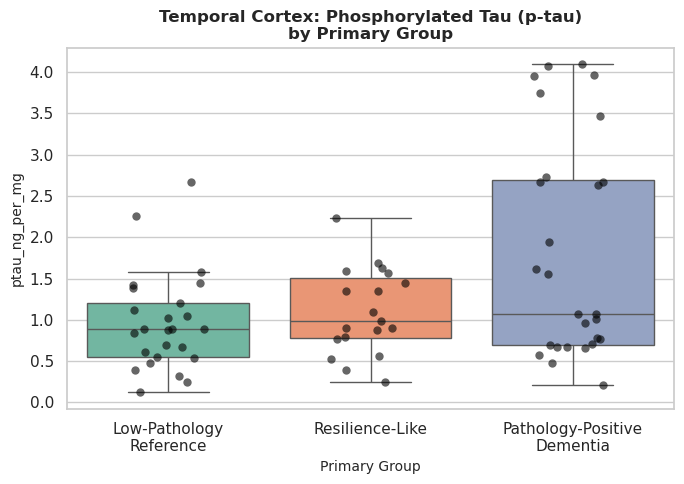

Data Table CSV for: Phosphorylated Tau (p-tau) (ptau_ng_per_mg)


/home/93252705-5e40-40c3-a3b6-36f1c71c49de/Allen Dataset/TCx_Donor_Table_ptau_ng_per_mg.csv

------------------------------------------------------------


/tmp/ipykernel_521/3508119698.py:36: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/tmp/ipykernel_521/3508119698.py:65: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(


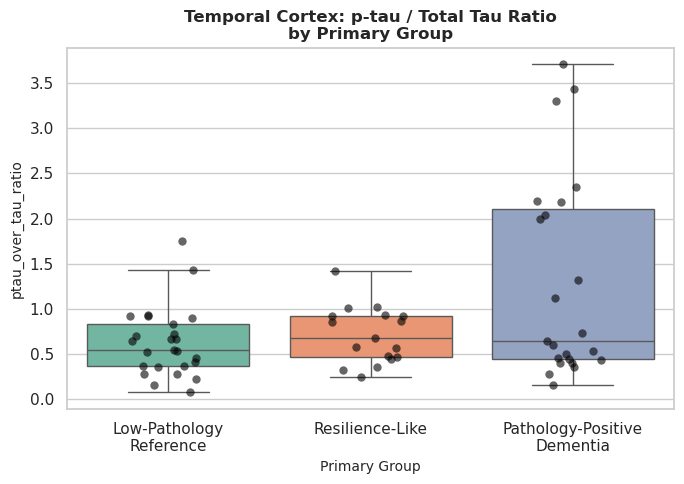

Data Table CSV for: p-tau / Total Tau Ratio (ptau_over_tau_ratio)


/home/93252705-5e40-40c3-a3b6-36f1c71c49de/Allen Dataset/TCx_Donor_Table_ptau_over_tau_ratio.csv

------------------------------------------------------------


/tmp/ipykernel_521/3508119698.py:36: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/tmp/ipykernel_521/3508119698.py:65: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(


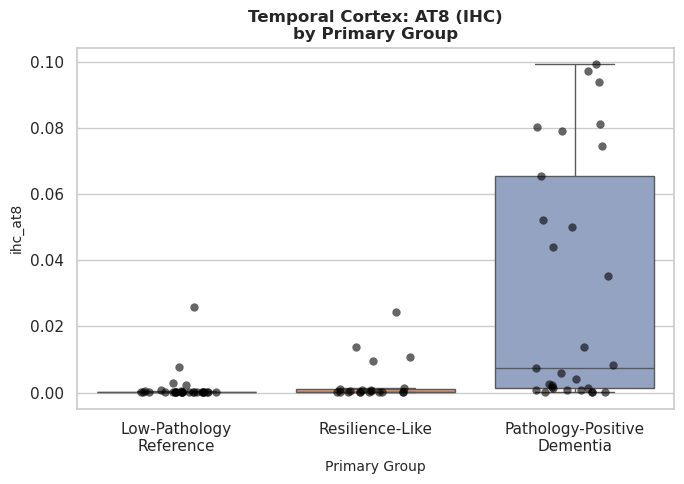

Data Table CSV for: AT8 (IHC) (ihc_at8)


/home/93252705-5e40-40c3-a3b6-36f1c71c49de/Allen Dataset/TCx_Donor_Table_ihc_at8.csv

------------------------------------------------------------


In [157]:
import os
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from IPython.display import FileLink, display

# 1. Define the 8 specific markers and clean display names
marker_dict = {
    "ptau_ng_per_mg": "Phosphorylated Tau (p-tau)",
    "ptau_over_tau_ratio": "p-tau / Total Tau Ratio",
    "ihc_at8": "AT8 (IHC)",  # Use 'ihc_at8_ffpe' if that matches your column name[cite: 1]
}

# 2. Define target primary groups
target_groups = [
    "Low-pathology reference",
    "Resilience-like",
    "Pathology-positive dementia",
]

# 3. Filter hippocampal data for target groups
table_df = temp_df[temp_df["primary_group"].isin(target_groups)].copy()

# 4. Loop through each marker: Plot Graph + Export CSV Table + Display Link
for marker_col, marker_title in marker_dict.items():
  if marker_col not in table_df.columns:
    print(
        f"Warning: Column '{marker_col}' not found in DataFrame."
        " Skipping...\n"
    )
    continue

  # --- A. GENERATE GRAPH ---
  fig, ax = plt.subplots(figsize=(7, 5))

  sns.boxplot(
      data=table_df,
      x="primary_group",
      y=marker_col,
      order=target_groups,
      palette="Set2",
      showfliers=False,
      ax=ax,
  )

  sns.stripplot(
      data=table_df,
      x="primary_group",
      y=marker_col,
      order=target_groups,
      color="black",
      alpha=0.6,
      jitter=0.2,
      size=6,
      ax=ax,
  )

  ax.set_title(
      f"Temporal Cortex: {marker_title}\nby Primary Group",
      fontsize=12,
      fontweight="bold",
  )
  ax.set_xlabel("Primary Group", fontsize=10)
  ax.set_ylabel(marker_col, fontsize=10)
  ax.set_xticklabels(
      ["Low-Pathology\nReference", "Resilience-Like", "Pathology-Positive\nDementia"]
  )

  plt.tight_layout()

  # Save Graph as PDF
  pdf_filename = f"Temporal Cortex_{marker_col}_distribution.pdf"
  plt.savefig(pdf_filename, format="pdf", bbox_inches="tight")
  plt.show()

  # --- B. CREATE & SAVE CSV DATA TABLE ---
  donor_table = (
      table_df[["donor_id", "primary_group", marker_col]]
      .sort_values(by=["primary_group", "donor_id"])
      .reset_index(drop=True)
  )

  # Save CSV File
  csv_filename = f"TCx_Donor_Table_{marker_col}.csv"
  donor_table.to_csv(csv_filename, index=False)

  # Display download links in Jupyter Notebook
  print(f"Data Table CSV for: {marker_title} ({marker_col})")
  display(FileLink(csv_filename))
  print("-" * 60)

In [158]:
# Import necessary libraries
import pandas as pd
import numpy as np
from scipy import stats

# Define Cliff's delta function if not already defined


def cliffs_delta(x, y):
    """Calculate Cliff's delta effect size"""
    x = np.array(x)
    y = np.array(y)
    
    if len(x) == 0 or len(y) == 0:
        return np.nan
    
    # Calculate all pairwise comparisons
    diff_matrix = x[:, np.newaxis] - y[np.newaxis, :]
    
    # Count differences
    greater = np.sum(diff_matrix > 0)
    less = np.sum(diff_matrix < 0)
    
    # Calculate Cliff's delta
    delta = (greater - less) / (len(x) * len(y))
    return delta

# Define markers dictionary
markers = {
    "ihc_at8": "AT8",
    "ptau_ng_per_mg": "p-tau", 
    "ptau_over_tau_ratio": "p-tau/total tau ratio"
}

# Filter data for temporal cortex (adjust "TCx" to match your actual structure acronym)
tcx_df = merged_df[merged_df["structure_acronym"] == "TCx"].copy()

# Initialize results list
tcx_results = []

# Calculate statistics for each marker
for col, name in markers.items():
    # Extract values for each group (adjust group column name and values as needed)
    res_vals = tcx_df[tcx_df["primary_group"] == "Resilience-like"][col].dropna()
    dem_vals = tcx_df[tcx_df["primary_group"] == "Pathology-positive dementia"][col].dropna()
    
    # Perform Mann-Whitney U test
    u_stat, p_val = stats.mannwhitneyu(res_vals, dem_vals, alternative="two-sided")
    
    # Calculate Cliff's delta
    c_delta = cliffs_delta(res_vals, dem_vals)
    
    # Compile results
    tcx_results.append({
        "Marker": name,
        "Resilience_N": len(res_vals),
        "Resilience_Median": res_vals.median(),
        "Resilience_Q1": res_vals.quantile(0.25),
        "Resilience_Q3": res_vals.quantile(0.75),
        "Resilience_IQR": res_vals.quantile(0.75) - res_vals.quantile(0.25),
        "Dementia_N": len(dem_vals),
        "Dementia_Median": dem_vals.median(),
        "Dementia_Q1": dem_vals.quantile(0.25),
        "Dementia_Q3": dem_vals.quantile(0.75),
        "Dementia_IQR": dem_vals.quantile(0.75) - dem_vals.quantile(0.25),
        "U_Statistic": u_stat,
        "Cliffs_Delta": c_delta,
        "p_value_raw": p_val,
    })

# Create DataFrame
tcx_table = pd.DataFrame(tcx_results)

# Apply Benjamini-Hochberg FDR correction
tcx_table["p_value_fdr"] = stats.false_discovery_control(tcx_table["p_value_raw"])

# Round numerical values for better presentation
numerical_cols = ["Resilience_Median", "Resilience_Q1", "Resilience_Q3", "Resilience_IQR",
                  "Dementia_Median", "Dementia_Q1", "Dementia_Q3", "Dementia_IQR",
                  "Cliffs_Delta", "p_value_raw", "p_value_fdr"]

for col in numerical_cols:
    if col in ["p_value_raw", "p_value_fdr"]:
        tcx_table[col] = tcx_table[col].round(6)  # More precision for p-values
    else:
        tcx_table[col] = tcx_table[col].round(4)

# Display the finalized temporal cortex statistical table
print("=== Temporal Cortex Statistical Results ===")
print("Markers: AT8, p-tau, and p-tau/total tau ratio")
print("Groups: Resilience-like vs Pathology-positive dementia")
print()
display(tcx_table)

# Export results
tcx_table.to_csv("Temporal_Cortex_Statistical_Results.csv", index=False)
print(f"\nResults exported to: Temporal_Cortex_Statistical_Results.csv")

# Display summary statistics
print("\n=== Summary ===")
significant_markers = tcx_table[tcx_table["p_value_fdr"] < 0.05]
print(f"Number of markers with significant differences (FDR < 0.05): {len(significant_markers)}")
if len(significant_markers) > 0:
    print("Significant markers:")
    for _, row in significant_markers.iterrows():
        print(f"  - {row['Marker']}: p_fdr = {row['p_value_fdr']:.6f}, Cliff's δ = {row['Cliffs_Delta']:.4f}")

=== Temporal Cortex Statistical Results ===
Markers: AT8, p-tau, and p-tau/total tau ratio
Groups: Resilience-like vs Pathology-positive dementia



,Marker,Resilience_N,Resilience_Median,Resilience_Q1,Resilience_Q3,Resilience_IQR,Dementia_N,Dementia_Median,Dementia_Q1,Dementia_Q3,Dementia_IQR,U_Statistic,Cliffs_Delta,p_value_raw,p_value_fdr
0,AT8,20,0.0003,0.0001,0.0012,0.0011,29,0.0074,0.0012,0.0656,0.0644,109.0,-0.6241,0.000241,0.000723
1,p-tau,19,0.9807,0.7831,1.5080,0.7249,27,1.0677,0.6991,2.6995,2.0004,201.0,-0.2164,0.219821,0.329732
2,p-tau/total tau ratio,17,0.6750,0.4636,0.9239,0.4603,23,0.6480,0.4383,2.1115,1.6733,165.0,-0.1560,0.411766,0.411766



Results exported to: Temporal_Cortex_Statistical_Results.csv

=== Summary ===
Number of markers with significant differences (FDR < 0.05): 1
Significant markers:
  - AT8: p_fdr = 0.000723, Cliff's δ = -0.6241


In [159]:
import pandas as pd

# 1. Ensure Hippocampus (HIP) results are calculated
hip_df = merged_df[merged_df["structure_acronym"] == "HIP"].copy()
hip_results = []

for col, name in markers.items():
    res_vals = hip_df[hip_df["primary_group"] == "Resilience-like"][col].dropna()
    dem_vals = hip_df[hip_df["primary_group"] == "Pathology-positive dementia"][col].dropna()

    u_stat, p_val = stats.mannwhitneyu(res_vals, dem_vals, alternative="two-sided")
    c_delta = cliffs_delta(res_vals, dem_vals)

    hip_results.append({
        "Marker": name,
        "HIP_Cliffs_Delta": c_delta,
        "HIP_p_value_raw": p_val,
    })

hip_table = pd.DataFrame(hip_results)
hip_table["HIP_p_value_fdr"] = stats.false_discovery_control(hip_table["HIP_p_value_raw"])

# Round HIP values for clean presentation
hip_table["HIP_Cliffs_Delta"] = hip_table["HIP_Cliffs_Delta"].round(4)
hip_table["HIP_p_value_fdr"] = hip_table["HIP_p_value_fdr"].round(6)

# 2. Build Side-by-Side Comparison Table (HIP vs TCx)
comparison_table = pd.DataFrame({
    "Marker": tcx_table["Marker"],
    "TCx Cliff's Delta": tcx_table["Cliffs_Delta"],
    "TCx FDR p-value": tcx_table["p_value_fdr"],
    "HIP Cliff's Delta": hip_table["HIP_Cliffs_Delta"],
    "HIP FDR p-value": hip_table["HIP_p_value_fdr"],
})

# Display comparison table
print("=== Side-by-Side Regional Comparison (TCx vs HIP) ===")
display(comparison_table)

# Export comparison table
comparison_table.to_csv("HIP_vs_TCx_Comparison.csv", index=False)
print("\nComparison table exported to: HIP_vs_TCx_Comparison.csv")

=== Side-by-Side Regional Comparison (TCx vs HIP) ===


,Marker,TCx Cliff's Delta,TCx FDR p-value,HIP Cliff's Delta,HIP FDR p-value
0,AT8,-0.6241,0.000723,-0.6007,0.001512
1,p-tau,-0.2164,0.329732,-0.4525,0.013451
2,p-tau/total tau ratio,-0.1560,0.411766,-0.4751,0.013451



Comparison table exported to: HIP_vs_TCx_Comparison.csv


In [166]:
import pandas as pd
import numpy as np
from scipy import stats

# 1. Define Cliff's Delta effect size function
def cliffs_delta(x, y):
    n1, n2 = len(x), len(y)
    if n1 == 0 or n2 == 0:
        return np.nan
    delta = 0
    for xi in x:
        for yi in y:
            if xi > yi:
                delta += 1
            elif xi < yi:
                delta -= 1
    return delta / (n1 * n2)

# 2. Define strict group classification function
def set_strict_group(row):
    braak = row.get("braak")
    cerad = row.get("cerad")
    dementia = row.get("act_demented")
    if braak in [5, 6] and cerad in [2, 3] and dementia == "No Dementia":
        return "Strict resilience-like"
    elif braak in [5, 6] and cerad in [2, 3] and dementia == "Dementia":
        return "Strict pathology-positive dementia"
    return None

# 3. Ensure strict_group exists in donor_df
if "strict_group" not in donor_df.columns:
    donor_df["strict_group"] = donor_df.apply(set_strict_group, axis=1)

# Remove strict_group from merged_df if it's already there to prevent duplication errors
if "strict_group" in merged_df.columns:
    merged_df.drop(columns=["strict_group"], inplace=True)

# Merge strict_group safely back into merged_df
merged_df = pd.merge(
    merged_df,
    donor_df[["donor_id", "strict_group"]],
    on="donor_id",
    how="left"
)

# Filter merged_df for Hippocampus (HIP) and strict groups
hip_strict = merged_df[
    (merged_df["structure_acronym"] == "HIP") &
    (merged_df["strict_group"].isin(["Strict resilience-like", "Strict pathology-positive dementia"]))
].copy()

markers = {
    "ihc_at8": "AT8 (IHC)",
    "ptau_ng_per_mg": "Phosphorylated Tau (p-tau)",
    "ptau_over_tau_ratio": "p-tau / Total Tau Ratio"
}

sensitivity_results = []
for col, name in markers.items():
    res_vals = hip_strict[hip_strict["strict_group"] == "Strict resilience-like"][col].dropna()
    dem_vals = hip_strict[hip_strict["strict_group"] == "Strict pathology-positive dementia"][col].dropna()
    
    if len(res_vals) > 0 and len(dem_vals) > 0:
        u_stat, p_val = stats.mannwhitneyu(res_vals, dem_vals, alternative="two-sided")
        c_delta = cliffs_delta(res_vals, dem_vals)
    else:
        u_stat, p_val, c_delta = np.nan, np.nan, np.nan
        
    sensitivity_results.append({
        "Marker": name,
        "Strict_Resilience_N": len(res_vals),
        "Strict_Resilience_Median": res_vals.median() if len(res_vals) > 0 else np.nan,
        "Strict_Dementia_N": len(dem_vals),
        "Strict_Dementia_Median": dem_vals.median() if len(dem_vals) > 0 else np.nan,
        "U_Statistic": u_stat,
        "Cliffs_Delta": c_delta,
        "p_value_raw": p_val,
    })

# Create DataFrame and display results
sensitivity_df = pd.DataFrame(sensitivity_results)
display(sensitivity_df)
sensitivity_df.to_csv("HIP_Strict_Group_Sensitivity_Analysis.csv", index=False)
print("\nSensitivity analysis completed and exported successfully!")

,Marker,Strict_Resilience_N,Strict_Resilience_Median,Strict_Dementia_N,Strict_Dementia_Median,U_Statistic,Cliffs_Delta,p_value_raw
0,AT8 (IHC),5,0.047639,21,0.059201,34.0,-0.352381,0.250350
1,Phosphorylated Tau (p-tau),4,3.300808,18,4.462014,23.0,-0.361111,0.300205
2,p-tau / Total Tau Ratio,4,2.515189,18,3.584856,16.0,-0.555556,0.098154



Sensitivity analysis completed and exported successfully!


In [170]:
import numpy as np
import pandas as pd


# Helper function to calculate Cliff's Delta effect size
def cliffs_delta(x, y):
    n_x, n_y = len(x), len(y)
    if n_x == 0 or n_y == 0:
        return np.nan
    diffs = np.subtract.outer(x, y)
    greater = np.sum(diffs > 0)
    less = np.sum(diffs < 0)
    return (greater - less) / (n_x * n_y)


# Set random seed for reproducibility
np.random.seed(42)

# Configuration settings
n_resamples = 10000
marker_col = "ihc_at8"
marker_label = "AT8 (IHC)"

group_res = "Resilience-like"
group_dem = "Pathology-positive dementia"

# Target regions to analyze (HIP prioritized first)
regions = {
    "HIP": "Hippocampus",
    "TCx": "Temporal Cortex",
}

analysis_results = []

for region_code, region_name in regions.items():
    # Filter dataset by region
    region_df = merged_df[merged_df["structure_acronym"] == region_code]

    # Extract target group values and drop NaNs
    res_vals = region_df[region_df["primary_group"] == group_res][
        marker_col
    ].dropna().values
    dem_vals = region_df[region_df["primary_group"] == group_dem][
        marker_col
    ].dropna().values

    n_res = len(res_vals)
    n_dem = len(dem_vals)

    if n_res == 0 or n_dem == 0:
        print(
            f"Warning: Missing group data for {marker_label} in {region_name}. Skipping."
        )
        continue

    # Observed point estimates
    obs_res_med = np.median(res_vals)
    obs_dem_med = np.median(dem_vals)
    obs_med_diff = obs_res_med - obs_dem_med
    obs_delta = cliffs_delta(res_vals, dem_vals)

    #  Bootstrap 95% Confidence Intervals (10,000 iterations)
    boot_diffs = []
    boot_deltas = []

    for _ in range(n_resamples):
        res_boot = np.random.choice(res_vals, size=n_res, replace=True)
        dem_boot = np.random.choice(dem_vals, size=n_dem, replace=True)

        boot_diffs.append(np.median(res_boot) - np.median(dem_boot))
        boot_deltas.append(cliffs_delta(res_boot, dem_boot))

    diff_ci_lower = np.percentile(boot_diffs, 2.5)
    diff_ci_upper = np.percentile(boot_diffs, 97.5)

    delta_ci_lower = np.percentile(boot_deltas, 2.5)
    delta_ci_upper = np.percentile(boot_deltas, 97.5)

    # Permutation Test for Median Difference (10,000 iterations)
    combined = np.concatenate([res_vals, dem_vals])
    perm_diffs = []

    for _ in range(n_resamples):
        shuffled = np.random.permutation(combined)
        perm_res = shuffled[:n_res]
        perm_dem = shuffled[n_res:]
        perm_diffs.append(np.median(perm_res) - np.median(perm_dem))

    perm_diffs = np.array(perm_diffs)
    # Two-sided p-value calculation
    permutation_p_val = np.mean(np.abs(perm_diffs) >= np.abs(obs_med_diff))

    # Append complete result row
    analysis_results.append(
        {
            "Region_Code": region_code,
            "Region_Name": region_name,
            "Marker": marker_label,
            "Resilience_N": n_res,
            "Dementia_N": n_dem,
            "Observed_Median_Diff": round(obs_med_diff, 4),
            "Median_Diff_95_CI": f"[{diff_ci_lower:.4f}, {diff_ci_upper:.4f}]",
            "Observed_Cliffs_Delta": round(obs_delta, 4),
            "Cliffs_Delta_95_CI": f"[{delta_ci_lower:.4f}, {delta_ci_upper:.4f}]",
            "Permutation_p_value": round(permutation_p_val, 6)
            if permutation_p_val >= 0.0001
            else "< 0.0001",
        }
    )

# Convert results into a DataFrame
at8_advanced_summary = pd.DataFrame(analysis_results)

# Display table
print("=== AT8 BOOTSTRAP & PERMUTATION ANALYSIS RESULTS ===")
display(at8_advanced_summary)

# Export results
at8_advanced_summary.to_csv(
    "AT8_Bootstrap_Permutation_Summary.csv", index=False
)
print("\nResults exported to: AT8_Bootstrap_Permutation_Summary.csv")

=== AT8 BOOTSTRAP & PERMUTATION ANALYSIS RESULTS ===


,Region_Code,Region_Name,Marker,Resilience_N,Dementia_N,Observed_Median_Diff,Median_Diff_95_CI,Observed_Cliffs_Delta,Cliffs_Delta_95_CI,Permutation_p_value
0,HIP,Hippocampus,AT8 (IHC),19,29,-0.0303,"[-0.0496, -0.0080]",-0.6007,"[-0.8258, -0.3212]",0.0019
1,TCx,Temporal Cortex,AT8 (IHC),20,29,-0.0071,"[-0.0499, -0.0012]",-0.6241,"[-0.8448, -0.3621]",0.0526



Results exported to: AT8_Bootstrap_Permutation_Summary.csv


/tmp/ipykernel_365/81817686.py:64: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/tmp/ipykernel_365/81817686.py:91: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


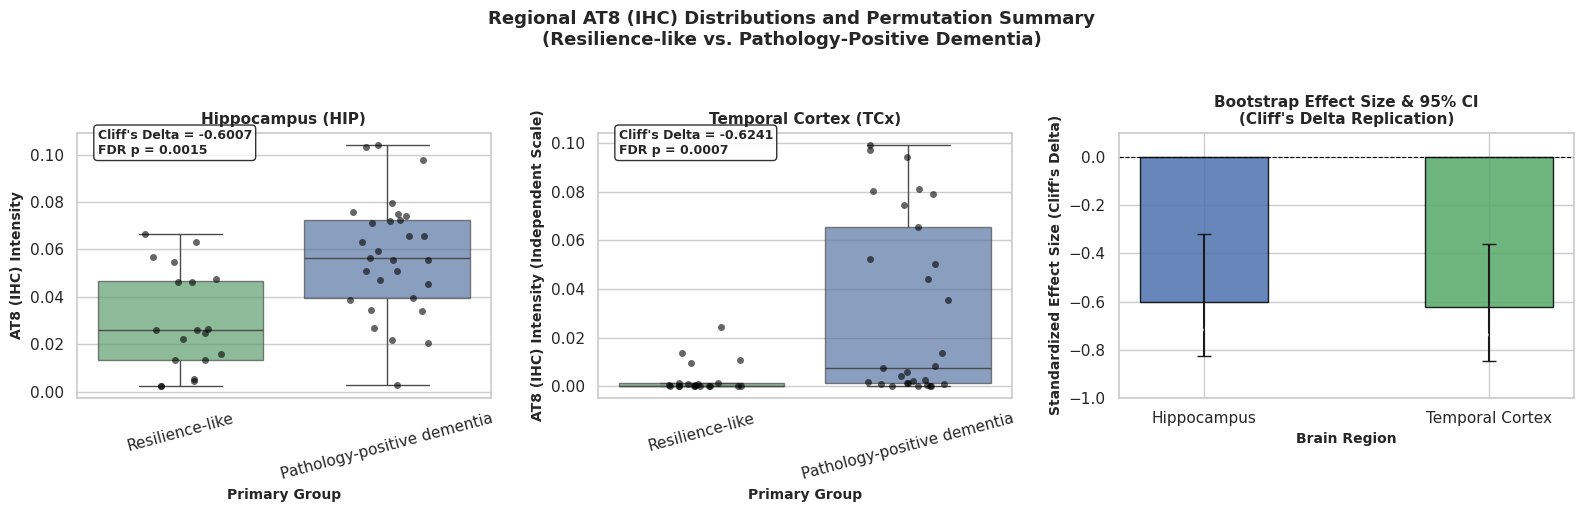

Updated 3-panel figure exported successfully to: AT8_3Panel_Permutation_CI_Figure.pdf


In [9]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# Set visual theme
sns.set_theme(style="whitegrid", context="notebook")

# Load original datasets and recreate merged_df
protein_df = pd.read_csv("ProteinAndPathologyQuantifications.csv")
donor_df = pd.read_csv("DonorInformation-2.csv")

def set_primary_group(row):
    nia = row.get("nia_reagan")
    dementia = row.get("act_demented")
    if nia in [2, 3] and dementia == "No Dementia":
        return "Resilience-like"
    elif nia in [2, 3] and dementia == "Dementia":
        return "Pathology-positive dementia"
    elif nia in [0, 1] and dementia == "No Dementia":
        return "Low-pathology reference"
    elif nia in [0, 1] and dementia == "Low-pathology dementia":
        return "Low-pathology dementia"
    return None

donor_df["primary_group"] = donor_df.apply(set_primary_group, axis=1)

merged_df = pd.merge(
    protein_df,
    donor_df[["donor_id", "primary_group"]],
    on="donor_id",
    how="left"
)

# Loading AT8 Bootstrap Permutation Summary File
try:
    perm_summary = pd.read_csv("AT8_Bootstrap_Permutation_Summary.csv")
except FileNotFoundError:
    perm_summary = pd.DataFrame({
        "Region_Name": ["Hippocampus", "Temporal Cortex"],
        "Observed_Cliffs_Delta": [-0.6007, -0.6241],
        "CI_Lower": [-0.8258, -0.8448],
        "CI_Upper": [-0.3212, -0.3621]
    })

# Configuration
target_groups = ["Resilience-like", "Pathology-positive dementia"]
palette = {"Resilience-like": "#55a868", "Pathology-positive dementia": "#4c72b0"}
marker_col = "ihc_at8"
marker_label = "AT8 (IHC)"

# Create a 3-panel figure layout (1 row, 3 columns)
fig, axes = plt.subplots(1, 3, figsize=(16, 5), gridspec_kw={'width_ratios': [1, 1, 1.1]})

# ----------------------------------------------------
# PANEL 1: Hippocampus AT8 Distribution & Stats
# ----------------------------------------------------
ax1 = axes[0]
hip_subset = merged_df[
    (merged_df["structure_acronym"] == "HIP") & 
    (merged_df["primary_group"].isin(target_groups))
].dropna(subset=[marker_col, "primary_group"])

sns.boxplot(
    data=hip_subset, x="primary_group", y=marker_col, order=target_groups,
    palette=palette, ax=ax1, boxprops=dict(alpha=0.7), fliersize=0
)
sns.stripplot(
    data=hip_subset, x="primary_group", y=marker_col, order=target_groups,
    color="black", alpha=0.6, size=5, jitter=0.2, ax=ax1
)
ax1.set_title("Hippocampus (HIP)", fontsize=11, fontweight="bold")
ax1.set_xlabel("Primary Group", fontsize=10, fontweight="bold")
ax1.set_ylabel(f"{marker_label} Intensity", fontsize=10, fontweight="bold")
ax1.tick_params(axis='x', rotation=15)
ax1.text(
    0.05, 0.92, "Cliff's Delta = -0.6007\nFDR p = 0.0015", 
    transform=ax1.transAxes, fontsize=9, fontweight="bold",
    bbox=dict(boxstyle="round,pad=0.3", fc="white", ec="black", alpha=0.8)
)

# ----------------------------------------------------
# PANEL 2: Temporal Cortex AT8 Distribution & Stats
# ----------------------------------------------------
ax2 = axes[1]
tcx_subset = merged_df[
    (merged_df["structure_acronym"] == "TCx") & 
    (merged_df["primary_group"].isin(target_groups))
].dropna(subset=[marker_col, "primary_group"])

sns.boxplot(
    data=tcx_subset, x="primary_group", y=marker_col, order=target_groups,
    palette=palette, ax=ax2, boxprops=dict(alpha=0.7), fliersize=0
)
sns.stripplot(
    data=tcx_subset, x="primary_group", y=marker_col, order=target_groups,
    color="black", alpha=0.6, size=5, jitter=0.2, ax=ax2
)
ax2.set_title("Temporal Cortex (TCx)", fontsize=11, fontweight="bold")
ax2.set_xlabel("Primary Group", fontsize=10, fontweight="bold")
ax2.set_ylabel(f"{marker_label} Intensity (Independent Scale)", fontsize=10, fontweight="bold")
ax2.tick_params(axis='x', rotation=15)
ax2.text(
    0.05, 0.92, "Cliff's Delta = -0.6241\nFDR p = 0.0007", 
    transform=ax2.transAxes, fontsize=9, fontweight="bold",
    bbox=dict(boxstyle="round,pad=0.3", fc="white", ec="black", alpha=0.8)
)

# ----------------------------------------------------
# PANEL 3: Cliff's Delta & 95% CI from Permutation Summary
# ----------------------------------------------------
ax3 = axes[2]
regions_summary = perm_summary["Region_Name"]
delta_values = perm_summary["Observed_Cliffs_Delta"]

# If CI is stored as a string column like "[-0.8258, -0.3212]", parse it or use explicit columns
if "Cliffs_Delta_95_CI" in perm_summary.columns:
    import ast
    ci_parsed = perm_summary["Cliffs_Delta_95_CI"].apply(lambda x: ast.literal_eval(x) if isinstance(x, str) else [-0.8258, -0.3212])
    ci_lower = [c[0] for c in ci_parsed]
    ci_upper = [c[1] for c in ci_parsed]
else:
    ci_lower = [-0.8258, -0.8448]
    ci_upper = [-0.3212, -0.3621]

y_errs = [[abs(val - l) for val, l in zip(delta_values, ci_lower)],
          [abs(u - val) for val, u in zip(delta_values, ci_upper)]]

bars = ax3.bar(
    regions_summary, delta_values, yerr=y_errs, capsize=5,
    color=["#4c72b0", "#55a868"], width=0.45, edgecolor="black", alpha=0.85
)
ax3.set_title("Bootstrap Effect Size & 95% CI\n(Cliff's Delta Replication)", fontsize=11, fontweight="bold")
ax3.set_xlabel("Brain Region", fontsize=10, fontweight="bold")
ax3.set_ylabel("Standardized Effect Size (Cliff's Delta)", fontsize=10, fontweight="bold")
ax3.set_ylim(-1.0, 0.1)
ax3.axhline(0, color="black", linewidth=0.8, linestyle="--")

for bar, val in zip(bars, delta_values):
    ax3.annotate(
        f"{val:.4f}",
        xy=(bar.get_x() + bar.get_width() / 2, val),
        xytext=(0, -15), textcoords="offset points",
        ha="center", va="top", fontsize=9, fontweight="bold", color="white"
    )

plt.suptitle(
    f"Regional {marker_label} Distributions and Permutation Summary\n(Resilience-like vs. Pathology-Positive Dementia)",
    fontsize=13, fontweight="bold", y=1.02
)

plt.tight_layout()

# Save and show
output_pdf = "AT8_3Panel_Permutation_CI_Figure.pdf"
plt.savefig(output_pdf, format="pdf", bbox_inches="tight")
plt.show()

print(f"Updated 3-panel figure exported successfully to: {output_pdf}")